# Project 2, Task 1: Analysis of the DAVIS and KIBA drug–target datasets

This notebook covers the whole of Task 1. It downloads both datasets, shows their format, cleans and deduplicates them, plots the heatmaps and score distributions, and then runs a few extra analyses that explain ligand and target behaviour and set up Tasks 2 and 3.

Every number quoted in the markdown cells is printed by a code cell above it, so it can be checked.

**Sources.** Data files come from the DeepDTA repository (Öztürk et al., 2018). The loading code (`pickle` with `latin1` encoding, JSON dictionaries read in file order) follows the format used in that repository. The pKd conversion follows the project brief. Everything else is our own code.

In [1]:
import os, json, pickle, urllib.request, warnings
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

SEED = 42
rng = np.random.default_rng(SEED)
for d in ["data/davis", "data/kiba", "data/processed", "figures", "results"]:
    os.makedirs(d, exist_ok=True)

## 1. Download and overview

We use the off-the-shelf DeepDTA files. Each dataset has three files. `Y` is the ligand × target score matrix (pickled NumPy array), `ligands_can.txt` maps ligand ID to canonical SMILES, and `proteins.txt` maps target ID to amino-acid sequence. Row *i* of `Y` is the *i*-th ligand in `ligands_can.txt` and column *j* is the *j*-th target in `proteins.txt`, so the JSON files must be read in file order.

In [2]:
BASE = "https://raw.githubusercontent.com/hkmztrk/DeepDTA/master/data/{}/{}"
for ds in ["davis", "kiba"]:
    for f in ["Y", "ligands_can.txt", "proteins.txt"]:
        path = f"data/{ds}/{f}"
        if not os.path.exists(path):
            urllib.request.urlretrieve(BASE.format(ds, f), path)

def load(ds):
    Y = pickle.load(open(f"data/{ds}/Y", "rb"), encoding="latin1").astype(float)
    lig = json.load(open(f"data/{ds}/ligands_can.txt"), object_pairs_hook=OrderedDict)
    pro = json.load(open(f"data/{ds}/proteins.txt"), object_pairs_hook=OrderedDict)
    assert Y.shape == (len(lig), len(pro))
    return Y, lig, pro

Y_d, lig_d, pro_d = load("davis")
Y_k, lig_k, pro_k = load("kiba")
print("DAVIS matrix:", Y_d.shape, " KIBA matrix:", Y_k.shape)

DAVIS matrix: (68, 442)  KIBA matrix: (2111, 229)


In [3]:
def to_long(Y, lig, pro, score_name):
    """Matrix -> one row per ligand-target position (missing positions kept as NaN for now)."""
    L, P = list(lig), list(pro)
    i, j = np.indices(Y.shape)
    return pd.DataFrame({
        "ligand_id": np.array(L, dtype=object)[i.ravel()],
        "target_id": np.array(P, dtype=object)[j.ravel()],
        "smiles": np.array(list(lig.values()), dtype=object)[i.ravel()],
        "sequence": np.array(list(pro.values()), dtype=object)[j.ravel()],
        score_name: Y.ravel(),
    })

davis_raw = to_long(Y_d, lig_d, pro_d, "Kd_nM")
kiba_raw = to_long(Y_k, lig_k, pro_k, "kiba_score")

def show_examples(df, score, n=5, seed=SEED):
    ex = df.dropna(subset=[score]).sample(n, random_state=seed).copy()
    ex["smiles"] = ex["smiles"].str.slice(0, 35) + "…"
    ex["sequence"] = ex["sequence"].str.slice(0, 25) + "…"
    return ex.reset_index(drop=True)

ex_d = show_examples(davis_raw, "Kd_nM")
ex_d["pKd"] = 9 - np.log10(ex_d["Kd_nM"])
ex_k = show_examples(kiba_raw, "kiba_score")
ex_d.to_csv("results/table1a_davis_examples.csv", index=False)
ex_k.to_csv("results/table1b_kiba_examples.csv", index=False)
print("Table 1a. Example DAVIS records (long format)")
display(ex_d)
print("Table 1b. Example KIBA records (long format)")
display(ex_k)

Table 1a. Example DAVIS records (long format)


,ligand_id,target_id,smiles,sequence,Kd_nM,pKd
0,16722836,ARK5,CC1=CN=C(N=C1NC2=CC(=CC=C2)S(=O)(=O…,MEGAAAPVAGDRPDLGLGAPGSPRE…,34.0,7.468521
1,4908365,PIK3CA(E545A),CN1CCN(CC1)C(=O)C2=CC3=C(N2)C=CC(=C…,TMPPRPSSGELWGIHLMPPRILVEC…,10000.0,5.000000
2,5291,RIPK5,CC1=C(C=C(C=C1)NC(=O)C2=CC=C(C=C2)C…,MEGDGVPWGSEPVSGPGPGGGGMIR…,10000.0,5.000000
3,5328940,FLT3(D835H),CN1CCN(CC1)CCCOC2=C(C=C3C(=C2)N=CC(…,MPALARDGGQLPLLVVFSAMIFGTI…,1000.0,6.000000
4,24779724,PIP5K2C,CN1C=C(C=N1)C2=NN3C(=NN=C3SC4=CC5=C…,MASSSVPPATVSAATAGPGPGFGFA…,3300.0,5.481486


Table 1b. Example KIBA records (long format)


,ligand_id,target_id,smiles,sequence,kiba_score
0,CHEMBL2005475,Q9Y6M4,C1CCC(CC1)CNC(=O)C2=CC3=C(NN=C3S2)C…,MENKKKDKDKSDDRMARPSGRSGHN…,11.300000
1,CHEMBL185569,O96013,CC1=CC(=CC=C1)NC(=O)NC2=CC=C(C=C2)C…,MFGKRKKRVEISAPSNFEHRVHTGF…,11.400000
2,CHEMBL1980142,Q13464,C1=CC2=C(C=CN=C2C(=C1)C(F)(F)F)NC(=…,MSTGDSFETRFEKMDNLLRDPKSEV…,11.100000
3,CHEMBL1242477,P42345,CC(C)N1C2=C(C(=N1)C3=CC4=C(C=C3)C=N…,MLGTGPAAATTAATTSSNVSVLQQF…,12.020819
4,CHEMBL2000685,P45983,CC(=NN=C(N)N)C1=CC(=CC(=C1)NC(=O)C2…,MSRSKRDNNFYSVEIGDSTFTVLKR…,11.800001


In [4]:
def lengths(lig, pro):
    s = pd.Series([len(x) for x in lig.values()]); p = pd.Series([len(x) for x in pro.values()])
    return {"SMILES length (median, min–max)": f"{s.median():.0f} ({s.min()}–{s.max()})",
            "Sequence length (median, min–max)": f"{p.median():.0f} ({p.min()}–{p.max()})"}

overview = pd.DataFrame({
    "DAVIS": {"Ligand ID type": "PubChem CID", "Target ID type": "Kinase gene name (incl. mutants)",
              "Score": "Kd (nM), lower = stronger", "Score used": "pKd = 9 − log10(Kd)",
              **lengths(lig_d, pro_d)},
    "KIBA": {"Ligand ID type": "ChEMBL ID", "Target ID type": "UniProt accession",
             "Score": "KIBA score (supplied scale), higher = stronger", "Score used": "KIBA score as supplied",
             **lengths(lig_k, pro_k)},
})
overview.to_csv("results/table2_dataset_overview.csv")
display(overview)

,DAVIS,KIBA
Ligand ID type,PubChem CID,ChEMBL ID
Target ID type,Kinase gene name (incl. mutants),UniProt accession
Score,"Kd (nM), lower = stronger","KIBA score (supplied scale), higher = stronger"
Score used,pKd = 9 − log10(Kd),KIBA score as supplied
"SMILES length (median, min–max)",60 (39–92),54 (20–590)
"Sequence length (median, min–max)",707 (244–2549),620 (215–4128)


**What the format tells us.** Both datasets are stored as a matrix plus two dictionaries, but they measure different things. DAVIS gives one assay type (Kd in nM), where *lower* means stronger binding, so we convert to pKd so that higher means stronger in both datasets. KIBA is already a composite score on a transformed scale where higher means stronger. Scores are therefore comparable *within* a dataset but not *across* the two, and we always analyse them separately. KIBA also includes some unusually long SMILES (up to 590 characters, against 92 in DAVIS) and longer sequences (up to 4,128 residues), which matters for any sequence-based model in Task 3.

## 2. Data cleaning

Our cleaning rules, applied in this order:

1. **Missing vs invalid.** In KIBA a NaN is an unmeasured pair. It is not a zero and not evidence of non-binding, so it is dropped from the observed set and only counted for sparsity. Any other non-finite value (inf) would be invalid and removed.
2. **DAVIS needs Kd > 0**, otherwise the log transform is undefined. We then convert to pKd.
3. **Abnormal values are flagged, never silently removed.** DAVIS Kd = 10,000 nM (pKd = 5) is the assay's screening limit, meaning "no binding detected up to 10 µM". The true Kd is ≥ 10 µM, so these are right-censored values. We keep them and add a `censored` flag. KIBA values far below the bulk of the distribution, including one exact zero, are flagged as `low_outlier` (score more than 3 × IQR below Q1) and kept, because the brief says to keep valid extreme or zero scores.
4. **Deduplication.** IDs are unique in both files, but the brief recommends SMILES and sequences as model inputs, and some different IDs share an identical SMILES or sequence. When the input is the string, those rows describe the same input pair, so we average their scores and record how many rows were merged and how much they disagreed.

In [5]:
def clean(df, ds):
    log = []
    n0 = len(df)
    score = "Kd_nM" if ds == "davis" else "kiba_score"
    is_nan = df[score].isna()
    is_inf = np.isinf(df[score])
    log.append(("Matrix positions", n0))
    log.append(("Missing (NaN, unmeasured)", int(is_nan.sum())))
    log.append(("Non-finite invalid (inf)", int(is_inf.sum())))
    df = df[~is_nan & ~is_inf].copy()
    if ds == "davis":
        bad = df["Kd_nM"] <= 0
        log.append(("Kd ≤ 0 (invalid)", int(bad.sum())))
        df = df[~bad].copy()
        df["score"] = 9 - np.log10(df["Kd_nM"])
        df["censored"] = df["Kd_nM"] >= 10000
        log.append(("Screening-limit Kd = 10,000 nM (kept, flagged)", int(df["censored"].sum())))
    else:
        df["score"] = df["kiba_score"]
        q1, q3 = df["score"].quantile([0.25, 0.75])
        lo = q1 - 3 * (q3 - q1)
        df["low_outlier"] = df["score"] < lo
        log.append((f"Low outliers < {lo:.2f} (kept, flagged)", int(df["low_outlier"].sum())))
        log.append(("Exact zero scores (kept, flagged)", int((df["score"] == 0).sum())))
    valid = len(df)
    log.append(("Valid observed pairs after cleaning", valid))
    return df.reset_index(drop=True), pd.DataFrame(log, columns=["step", ds.upper()])

davis_c, log_d = clean(davis_raw, "davis")
kiba_c, log_k = clean(kiba_raw, "kiba")
cleaning_log = log_d.merge(log_k, on="step", how="outer")
order = list(dict.fromkeys(list(log_d["step"]) + list(log_k["step"])))
order.remove("Valid observed pairs after cleaning"); order.append("Valid observed pairs after cleaning")
cleaning_log = cleaning_log.set_index("step").loc[order]
cleaning_log = cleaning_log.map(lambda v: "–" if pd.isna(v) else f"{int(v):,}")
cleaning_log.to_csv("results/table3_cleaning_log.csv")
display(cleaning_log)

,DAVIS,KIBA
step,,
Matrix positions,"30,056","483,419"
"Missing (NaN, unmeasured)",0,"365,165"
Non-finite invalid (inf),0,0
Kd ≤ 0 (invalid),0,–
"Screening-limit Kd = 10,000 nM (kept, flagged)","20,931",–
"Low outliers < 9.03 (kept, flagged)",–,20
"Exact zero scores (kept, flagged)",–,1
Valid observed pairs after cleaning,"30,056","118,254"


**Cleaning result.** Neither file contains infinite values or non-positive Kd, so no record is removed as invalid. The 365,165 missing KIBA positions are excluded from the observed set but kept in the sparsity count. Two kinds of abnormal record are kept and flagged.

* **DAVIS screening limit.** 20,931 of 30,056 pairs (69.6%) sit at exactly Kd = 10,000 nM. This is not a measured affinity but "weaker than the assay could detect". Deleting these rows would make DAVIS look like a dataset of strong binders, while keeping them unflagged would treat a lower bound as an exact value. We keep them with a `censored` flag so later tasks can choose how to handle them.
* **KIBA low outliers.** 20 scores fall more than 3 × IQR below Q1 (< 9.03). Ten of them come from a single ligand, CHEMBL373751, with values as low as 0.0 and 1.1, more than 10 units below the bulk. They are kept and flagged rather than removed, since the brief asks us to keep valid extreme or zero values, but they are a likely source of error in Task 2 because they will dominate squared-error metrics.

Before deduplicating, we check which IDs share a string.

In [6]:
def shared_strings(d, kind):
    s = pd.Series(d)
    groups = [list(g) for g in s.groupby(s).groups.values() if len(g) > 1]
    print(f"{kind}: {len(d)} IDs, {s.nunique()} unique strings, {len(groups)} groups of IDs sharing a string")
    return groups

g_dl = shared_strings(lig_d, "DAVIS ligands (SMILES)")
g_dp = shared_strings(pro_d, "DAVIS targets (sequence)")
g_kl = shared_strings(lig_k, "KIBA ligands (SMILES)")
g_kp = shared_strings(pro_k, "KIBA targets (sequence)")
print("\nDAVIS sequence-sharing groups:")
for g in sorted(g_dp, key=len, reverse=True):
    print(f"  {len(g):2d}: {', '.join(g[:6])}{' …' if len(g) > 6 else ''}")
print("\nLargest KIBA SMILES-sharing groups:", sorted(g_kl, key=len, reverse=True)[:2])

DAVIS ligands (SMILES): 68 IDs, 68 unique strings, 0 groups of IDs sharing a string
DAVIS targets (sequence): 442 IDs, 379 unique strings, 18 groups of IDs sharing a string
KIBA ligands (SMILES): 2111 IDs, 2068 unique strings, 32 groups of IDs sharing a string
KIBA targets (sequence): 229 IDs, 229 unique strings, 0 groups of IDs sharing a string

DAVIS sequence-sharing groups:
  15: ABL1(E255K), ABL1(F317I), ABL1(F317I)p, ABL1(F317L), ABL1(F317L)p, ABL1(H396P) …
  12: EGFR, EGFR(E746A750del), EGFR(G719C), EGFR(G719S), EGFR(L747E749del), EGFR(L747S752del) …
  10: PIK3CA, PIK3CA(C420R), PIK3CA(E542K), PIK3CA(E545A), PIK3CA(E545K), PIK3CA(H1047L) …
   8: KIT, KIT(A829P), KIT(D816H), KIT(D816V), KIT(L576P), KIT(V559D) …
   7: FLT3, FLT3(D835H), FLT3(D835Y), FLT3(ITD), FLT3(K663Q), FLT3(N841I) …
   4: RET, RET(M918T), RET(V804L), RET(V804M)
   3: MET, MET(M1250T), MET(Y1235D)
   2: BRAF, BRAF(V600E)
   2: LRRK2, LRRK2(G2019S)
   2: CDK4-cyclinD1, CDK4-cyclinD3
   2: RSK3(KinDom.1-N-terminal

DAVIS reuses the same wild-type sequence for kinase mutants (e.g. ABL1 and its T315I gatekeeper mutant, EGFR and T790M) and for different kinase domains of the same protein (e.g. JAK1 JH1 and JH2). KIBA reuses the same SMILES for some ChEMBL IDs, because the canonical SMILES supplied carries no stereochemistry, so stereoisomers collapse to one string.

Merging is "correct" for a sequence-based model, since it literally cannot tell these inputs apart. But it is not free. The cell below measures how much the merged rows disagreed.

In [7]:
def dedup(df, extra_flags):
    agg = {"score": ["mean", "std", "count", "min", "max"],
           "ligand_id": lambda x: "|".join(sorted(set(x))),
           "target_id": lambda x: "|".join(sorted(set(x)))}
    for f in extra_flags:
        agg[f] = "mean"
    out = df.groupby(["smiles", "sequence"]).agg(agg)
    out.columns = ["score", "score_sd", "n_merged", "score_min", "score_max", "ligand_ids", "target_ids"] + \
                  [f + "_frac" for f in extra_flags]
    out = out.reset_index()
    out["score_sd"] = out["score_sd"].fillna(0.0)
    out["score_range"] = out["score_max"] - out["score_min"]
    return out

davis_dd = dedup(davis_c, ["censored"])
kiba_dd = dedup(kiba_c, ["low_outlier"])

def conflict_summary(dd, name):
    m = dd[dd["n_merged"] > 1]
    return pd.Series({
        "Pair groups with >1 record": len(m),
        "Records absorbed by merging": int((m["n_merged"] - 1).sum()),
        "Mean within-group range": round(m["score_range"].mean(), 2),
        "Max within-group range": round(m["score_range"].max(), 2),
        "Groups with range > 1 log unit": int((m["score_range"] > 1).sum()),
    }, name=name)

conflicts = pd.concat([conflict_summary(davis_dd, "DAVIS"), conflict_summary(kiba_dd, "KIBA")], axis=1)
conflicts.to_csv("results/table5_duplicate_conflicts.csv")
display(conflicts)

worst = davis_dd.sort_values("score_range", ascending=False).head(5)
display(worst[["ligand_ids", "target_ids", "n_merged", "score_min", "score_max", "score_range"]]
        .assign(target_ids=lambda x: x["target_ids"].str.slice(0, 70) + "…"))

,DAVIS,KIBA
Pair groups with >1 record,1224.00,473.00
Records absorbed by merging,4284.00,597.00
Mean within-group range,0.50,0.37
Max within-group range,4.75,2.78
Groups with range > 1 log unit,260.00,61.00


,ligand_ids,target_ids,n_merged,score_min,score_max,score_range
9090,3062316,ABL1|ABL1(E255K)|ABL1(F317I)|ABL1(F317I)p|ABL1(F317L)|AB...,15,6.050610,10.795880,4.745270
8991,3062316,KIT|KIT(A829P)|KIT(D816H)|KIT(D816V)|KIT(L576P)|KIT(V559...,8,5.000000,9.244125,4.244125
24916,208908,EGFR|EGFR(E746A750del)|EGFR(G719C)|EGFR(G719S)|EGFR(L747...,12,5.000000,9.036212,4.036212
10227,5291,ABL1|ABL1(E255K)|ABL1(F317I)|ABL1(F317I)p|ABL1(F317L)|AB...,15,5.000000,8.958607,3.958607
22635,6450551,KIT|KIT(A829P)|KIT(D816H)|KIT(D816V)|KIT(L576P)|KIT(V559...,8,5.376751,9.309804,3.933053


In [8]:
def counts(df_obs, n_lig, n_tgt, lig_col, tgt_col):
    nl, nt = df_obs[lig_col].nunique(), df_obs[tgt_col].nunique()
    return {"Ligands": nl, "Targets": nt, "Observed pairs": len(df_obs),
            "Matrix positions": nl * nt, "Sparsity (missing / all positions)": f"{1 - len(df_obs) / (nl * nt):.2%}"}

count_table = pd.DataFrame({
    ("DAVIS", "Original (IDs)"): {"Ligands": Y_d.shape[0], "Targets": Y_d.shape[1],
                                  "Observed pairs": int(np.isfinite(Y_d).sum()), "Matrix positions": Y_d.size,
                                  "Sparsity (missing / all positions)": f"{1 - np.isfinite(Y_d).sum() / Y_d.size:.2%}"},
    ("DAVIS", "Cleaned (IDs)"): counts(davis_c, *Y_d.shape, "ligand_id", "target_id"),
    ("DAVIS", "Deduplicated (SMILES, sequence)"): counts(davis_dd, 0, 0, "smiles", "sequence"),
    ("KIBA", "Original (IDs)"): {"Ligands": Y_k.shape[0], "Targets": Y_k.shape[1],
                                 "Observed pairs": int(np.isfinite(Y_k).sum()), "Matrix positions": Y_k.size,
                                 "Sparsity (missing / all positions)": f"{1 - np.isfinite(Y_k).sum() / Y_k.size:.2%}"},
    ("KIBA", "Cleaned (IDs)"): counts(kiba_c, *Y_k.shape, "ligand_id", "target_id"),
    ("KIBA", "Deduplicated (SMILES, sequence)"): counts(kiba_dd, 0, 0, "smiles", "sequence"),
})
count_table.to_csv("results/table4_counts_original_vs_dedup.csv")
display(count_table)

DAVIS                \
                                   Original (IDs) Cleaned (IDs)   
Ligands                                        68            68   
Targets                                       442           442   
Observed pairs                              30056         30056   
Matrix positions                            30056         30056   
Sparsity (missing / all positions)          0.00%         0.00%   

                                                                    \
                                   Deduplicated (SMILES, sequence)   
Ligands                                                         68   
Targets                                                        379   
Observed pairs                                               25772   
Matrix positions                                             25772   
Sparsity (missing / all positions)                           0.00%   

                                             KIBA                \
                                   Original (IDs) Cleaned (IDs)   
Ligands                                      2111          2111   
Targets                                       229           229   
Observed pairs                             118254        118254   
Matrix positions                           483419        483419   
Sparsity (missing / all positions)         75.54%        75.54%   

                                                                    
                                   Deduplicated (SMILES, sequence)  
Ligands                                                       2068  
Targets                                                        229  
Observed pairs                                              117657  
Matrix positions                                            473572  
Sparsity (missing / all positions)                          75.16%

**What deduplication changes.** At ID level nothing is duplicated, so the "cleaned (IDs)" counts equal the originals: DAVIS stays 68 × 442 with 30,056 pairs and KIBA stays 2,111 × 229 with 118,254 pairs (75.54% missing). At the string level DAVIS drops from 442 to 379 targets and from 30,056 to 25,772 pairs, while KIBA drops from 2,111 to 2,068 ligands and from 118,254 to 117,657 pairs (75.16% missing).

The merged groups do not agree well. In DAVIS, 260 of 1,224 merged groups span more than one pKd unit, and the worst spans 4.75 units: the same ligand (3062316) binds some ABL1 mutants strongly and others hardly at all. These are real biological differences (drug-resistance mutations such as ABL1 T315I) that the supplied wild-type sequence hides. **Our decision** is to keep both versions. ID-level data keeps mutant-specific information and suits ID-based CF in Task 2. String-level data is required whenever SMILES or sequences are model inputs (Task 3), otherwise identical inputs would appear with different labels and could leak across train and test splits. We report the information lost by averaging instead of hiding it.

We save two cleaned versions of each dataset for Tasks 2 and 3.

* `*_clean_ids.csv` keeps one row per ID pair. Mutants stay separate, which suits the ID-based collaborative filtering in Task 2.
* `*_clean_dedup.csv` has one row per (SMILES, sequence) pair with averaged scores. Any model that reads strings (Task 3) must use this version, otherwise the same input pair could appear in both training and test with different labels.

In [9]:
# Strings are stored once in lookup tables (not repeated on every row) to keep the files small.
for ds, lig, pro in [("davis", lig_d, pro_d), ("kiba", lig_k, pro_k)]:
    pd.DataFrame({"ligand_id": list(lig), "smiles": list(lig.values())}).to_csv(f"data/processed/{ds}_ligands.csv", index=False)
    pd.DataFrame({"target_id": list(pro), "sequence": list(pro.values())}).to_csv(f"data/processed/{ds}_targets.csv", index=False)
davis_c[["ligand_id", "target_id", "Kd_nM", "score", "censored"]].to_csv("data/processed/davis_clean_ids.csv", index=False)
kiba_c[["ligand_id", "target_id", "kiba_score", "score", "low_outlier"]].to_csv("data/processed/kiba_clean_ids.csv", index=False)
# Dedup files: one row per (SMILES, sequence); ligand_key / target_key identify the string (look it up in the tables above)
for name, dd in [("davis", davis_dd), ("kiba", kiba_dd)]:
    out = dd.drop(columns=["smiles", "sequence"]).copy()
    # one fixed key per string: the alphabetically first ID among ALL IDs sharing that SMILES / sequence
    src = davis_c if name == "davis" else kiba_c
    lig_key = src.groupby("smiles")["ligand_id"].min(); tgt_key = src.groupby("sequence")["target_id"].min()
    out.insert(0, "ligand_key", dd["smiles"].map(lig_key).values)
    out.insert(1, "target_key", dd["sequence"].map(tgt_key).values)
    out.to_csv(f"data/processed/{name}_clean_dedup.csv", index=False)
print({f: f"{os.path.getsize('data/processed/' + f) / 1e6:.1f} MB" for f in sorted(os.listdir("data/processed"))})

{'davis_clean_dedup.csv': '1.8 MB', 'davis_clean_ids.csv': '1.1 MB', 'davis_ligands.csv': '0.0 MB', 'davis_targets.csv': '0.4 MB', 'kiba_clean_dedup.csv': '11.0 MB', 'kiba_clean_ids.csv': '6.1 MB', 'kiba_ligands.csv': '0.2 MB', 'kiba_targets.csv': '0.2 MB'}


## 3. Visualisation

### 3.1 Ligand–target heatmaps

Each dataset gets two views. The first shows the full matrix, so missing and screening-limit cells are visible, as the brief requires. The second hides those cells so only real affinity measurements are coloured, which is far easier to read.

* **Fig 1a, DAVIS, full matrix.** Rows and columns ordered by hierarchical clustering (Ward linkage on pKd profiles). Screening-limit cells (pKd = 5) get their own pale colour so they are not confused with weak but measured binding.
* **Fig 1b, DAVIS, binders only.** pKd = 5 cells are blanked to white, and we keep only targets bound (pKd > 5) by at least 3 ligands, so near-empty columns drop out.
* **Fig 2a, KIBA, full matrix.** KIBA cannot be clustered directly, because most cells are missing, so ligands and targets are ordered by how many measurements they have, which makes the sparsity pattern itself visible. Missing cells are light grey.
* **Fig 2b, KIBA, dense core.** We repeatedly remove the emptiest 2% of ligands or targets until at least 95% of the remaining cells are measured, then cluster the core. Gaps are filled with the ligand mean *for ordering only*; displayed colours are real values.

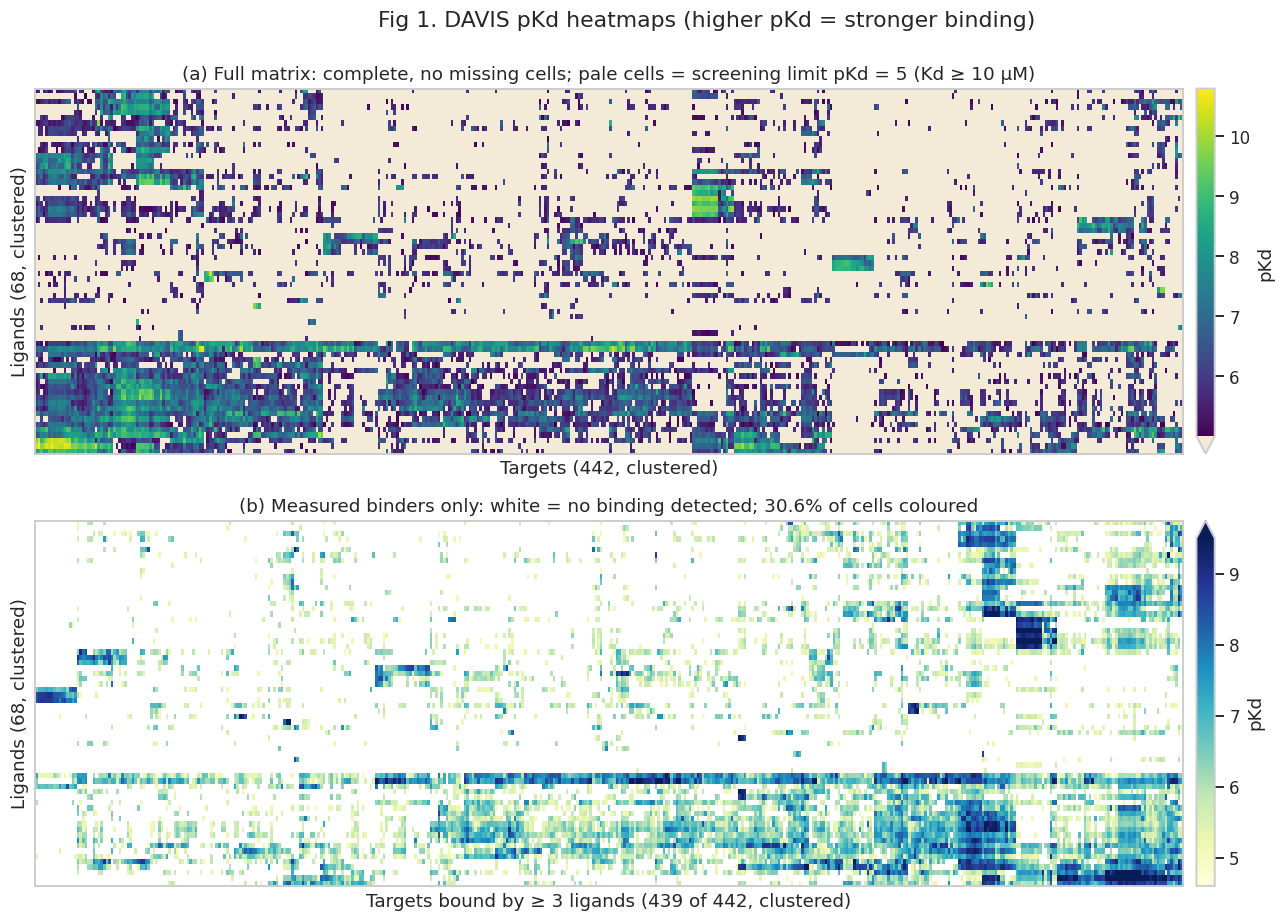

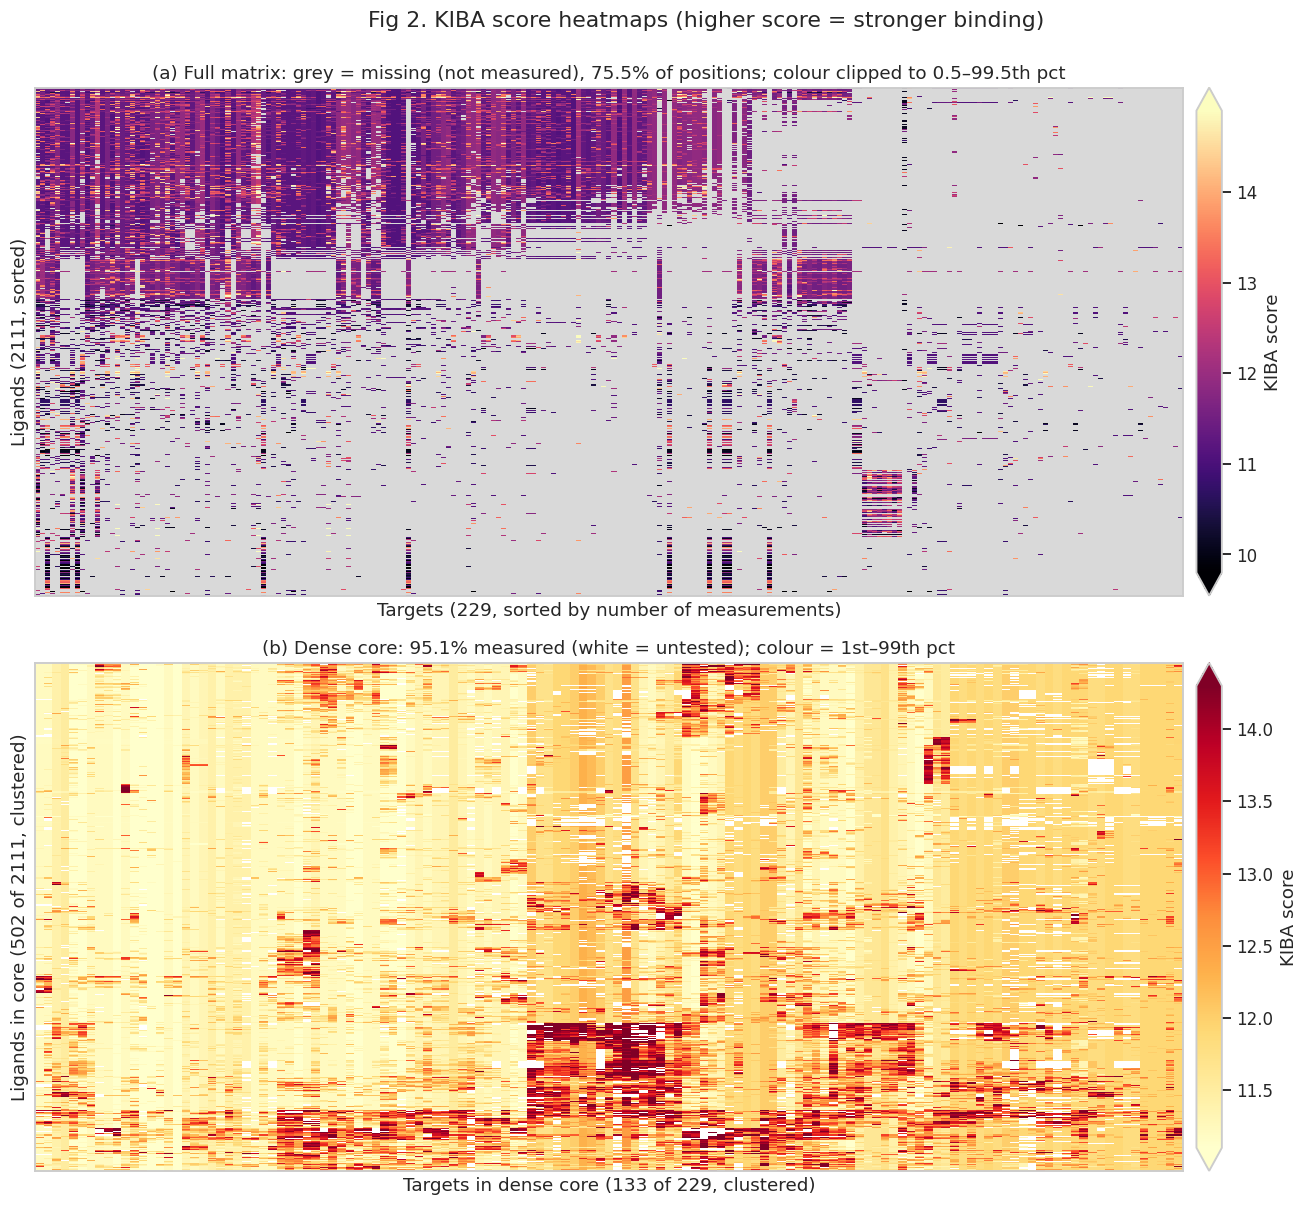

KIBA dense core: 502 ligands × 133 targets, 95.1% measured, 63,483 values (53.7% of all KIBA observations); median 11.70
Median spread (sd) across a core ligand's targets: 0.54;  across a core target's ligands: 0.58


In [10]:
M_d = davis_c.pivot(index="ligand_id", columns="target_id", values="score")
M_k = kiba_c.pivot(index="ligand_id", columns="target_id", values="score")
row_o = leaves_list(linkage(M_d.values, "ward"))
col_o = leaves_list(linkage(M_d.values.T, "ward"))
Md_ord = M_d.iloc[row_o, col_o]

fig, axes = plt.subplots(2, 1, figsize=(13, 8.4))
ax = axes[0]
cmap = plt.get_cmap("viridis").copy(); cmap.set_under("#f3ead7")
im = ax.imshow(Md_ord.values, aspect="auto", cmap=cmap, vmin=5.0001, vmax=Md_ord.values.max(), interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="min", pad=0.01); cb.set_label("pKd")
ax.set_xlabel(f"Targets ({M_d.shape[1]}, clustered)"); ax.set_ylabel(f"Ligands ({M_d.shape[0]}, clustered)")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("(a) Full matrix: complete, no missing cells; pale cells = screening limit pKd = 5 (Kd ≥ 10 µM)")

keep_t = (M_d > 5).sum(0) >= 3
Md_b = M_d.loc[:, keep_t]
ro = leaves_list(linkage(Md_b.values, "ward")); co = leaves_list(linkage(Md_b.values.T, "ward"))
show = Md_b.iloc[ro, co].where(Md_b.iloc[ro, co] > 5)
ax = axes[1]
cm = plt.get_cmap("YlGnBu").copy(); cm.set_bad("white")
im = ax.imshow(np.ma.masked_invalid(show.values), aspect="auto", cmap=cm, vmin=4.6, vmax=9.5, interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="max", pad=0.01); cb.set_label("pKd")
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel(f"Targets bound by ≥ 3 ligands ({show.shape[1]} of {M_d.shape[1]}, clustered)")
ax.set_ylabel(f"Ligands ({show.shape[0]}, clustered)")
ax.set_title(f"(b) Measured binders only: white = no binding detected; {show.notna().values.mean():.1%} of cells coloured")
fig.suptitle("Fig 1. DAVIS pKd heatmaps (higher pKd = stronger binding)", y=0.995)
fig.tight_layout(); fig.savefig("figures/fig1_davis_heatmaps.png"); plt.show()

r_k = M_k.notna().sum(1).sort_values(ascending=False).index
c_k = M_k.notna().sum(0).sort_values(ascending=False).index
Mk_ord = M_k.loc[r_k, c_k]
fig, axes = plt.subplots(2, 1, figsize=(13, 11))
ax = axes[0]
cmap2 = plt.get_cmap("magma").copy(); cmap2.set_bad("#d9d9d9")
vlo, vhi = np.nanpercentile(Mk_ord.values, [0.5, 99.5])
im = ax.imshow(np.ma.masked_invalid(Mk_ord.values), aspect="auto", cmap=cmap2, vmin=vlo, vmax=vhi, interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="both", pad=0.01); cb.set_label("KIBA score")
ax.set_xlabel(f"Targets ({M_k.shape[1]}, sorted by number of measurements)")
ax.set_ylabel(f"Ligands ({M_k.shape[0]}, sorted)")
ax.set_xticks([]); ax.set_yticks([])
sp = 1 - M_k.notna().values.mean()
ax.set_title(f"(a) Full matrix: grey = missing (not measured), {sp:.1%} of positions; colour clipped to 0.5–99.5th pct")

O = M_k.notna().values; rows = np.arange(O.shape[0]); cols = np.arange(O.shape[1])
while O[np.ix_(rows, cols)].mean() < 0.95:
    sub = O[np.ix_(rows, cols)]; rf, cf = sub.mean(1), sub.mean(0)
    if rf.min() <= cf.min():
        rows = rows[rf > (np.quantile(rf, 0.02) if len(rows) > 50 else rf.min())]
    else:
        cols = cols[cf > (np.quantile(cf, 0.02) if len(cols) > 20 else cf.min())]
core = M_k.iloc[rows, cols]
filled = core.apply(lambda r: r.fillna(r.mean()), axis=1)  # ordering only
ro = leaves_list(linkage(filled.values, "ward")); co = leaves_list(linkage(filled.values.T, "ward"))
core_o = core.iloc[ro, co]
ax = axes[1]
cm2 = plt.get_cmap("YlOrRd").copy(); cm2.set_bad("white")
lo_, hi_ = np.nanpercentile(core_o.values, [1, 99])
im = ax.imshow(np.ma.masked_invalid(core_o.values), aspect="auto", cmap=cm2, vmin=lo_, vmax=hi_, interpolation="nearest")
cb = fig.colorbar(im, ax=ax, extend="both", pad=0.01); cb.set_label("KIBA score")
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel(f"Targets in dense core ({core.shape[1]} of {M_k.shape[1]}, clustered)")
ax.set_ylabel(f"Ligands in core ({core.shape[0]} of {M_k.shape[0]}, clustered)")
ax.set_title(f"(b) Dense core: {core.notna().values.mean():.1%} measured (white = untested); colour = 1st–99th pct")
fig.suptitle("Fig 2. KIBA score heatmaps (higher score = stronger binding)", y=0.995)
fig.tight_layout(); fig.savefig("figures/fig2_kiba_heatmaps.png"); plt.show()
core_vals = core.values[~np.isnan(core.values)]
print(f"KIBA dense core: {core.shape[0]} ligands × {core.shape[1]} targets, {core.notna().values.mean():.1%} measured, "
      f"{len(core_vals):,} values ({len(core_vals) / len(kiba_c):.1%} of all KIBA observations); median {np.median(core_vals):.2f}")
print(f"Median spread (sd) across a core ligand's targets: {core.std(1).median():.2f};  across a core target's ligands: {core.std(0).median():.2f}")

**Heatmaps.** The two matrices look nothing alike.

DAVIS (Fig 1) is complete but mostly at its floor. Once the screening-limit cells are blanked (Fig 1b), only a third of cells carry a measured affinity, and those form clear blocks: tight dark blocks are selective ligands hitting a few related kinases hard, one dark stripe across the full width is the promiscuous ligand 44259 (staurosporine), and the broad lower band is ligands that bind widely but weakly. Dark vertical blocks are kinase groups that many ligands hit.

KIBA (Fig 2) is dominated by grey. Its observed cells form rectangular blocks, the signature of panel screening where a compound set is tested against a fixed kinase set. So missingness in KIBA is **structured, not random**: whether a pair is observed depends on which study the ligand came from, not on whether it binds. A missing cell therefore cannot be read as "does not bind". The dense core (Fig 2b) keeps 502 ligands and 133 targets at 95% measured, over half of all KIBA observations. There, vertical stripes are targets that score high against most ligands, horizontal bands are generally potent ligands, and the dark block at the lower middle is a group of ligands hitting one target family specifically, which is exactly the ligand-target interaction a recommender has to learn.

### 3.2 Score distributions (KDE)

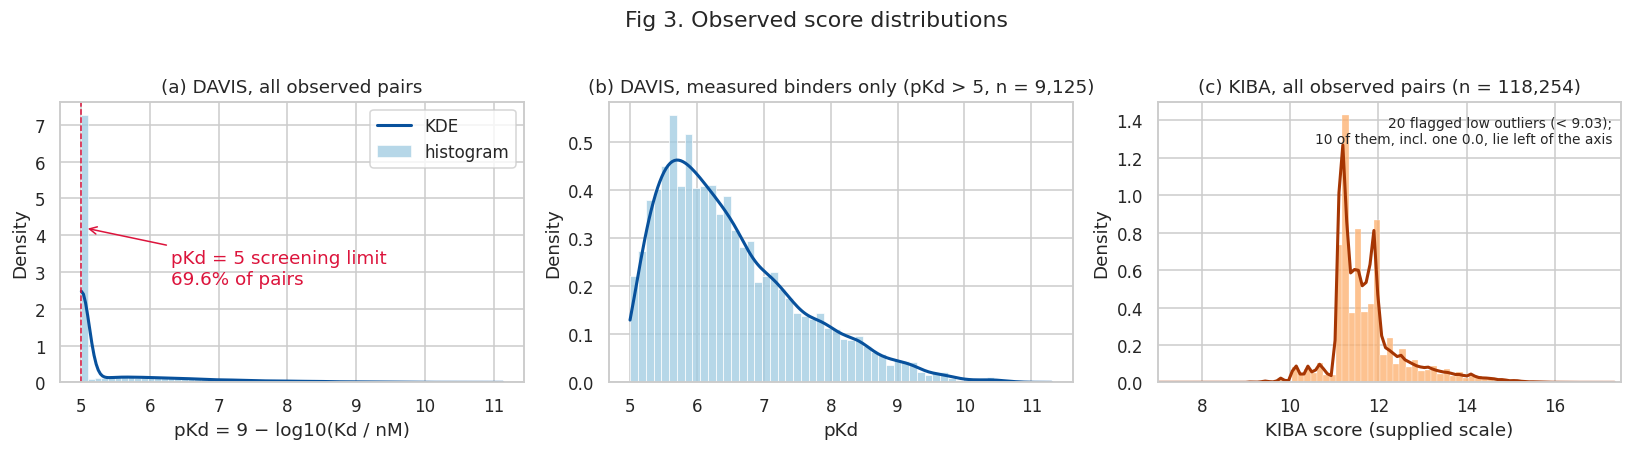

,DAVIS pKd (all),DAVIS pKd (> 5 only),KIBA score
n,30056.00,9125.00,118254.00
mean,5.45,6.49,11.72
sd,0.89,1.05,0.84
min,5.00,5.00,0.00
Q1,5.00,5.68,11.20
median,5.00,6.24,11.50
Q3,5.52,7.09,11.92
max,10.80,10.80,17.20
skew,2.30,0.98,1.16


Share of KIBA scores in 11.05–11.35: 31.1%
Share of KIBA scores that are exact multiples of 0.1: 84.3%
Ligand CHEMBL373751: 11 measurements, 10 of them flagged
KIBA flagged low outliers:


,ligand_id,target_id,score
103943,CHEMBL373751,P53350,0.000000
103939,CHEMBL373751,P00533,1.100000
103940,CHEMBL373751,P04626,1.100000
103941,CHEMBL373751,P49840,1.300000
103944,CHEMBL373751,P53779,1.300000
103942,CHEMBL373751,P49841,1.300000
103946,CHEMBL373751,Q15759,1.300000
103937,CHEMBL373751,O14920,6.100000
103938,CHEMBL373751,O15111,6.100000
103945,CHEMBL373751,Q14164,6.100004


In [11]:
d_all = davis_c["score"]; d_unc = davis_c.loc[~davis_c["censored"], "score"]
k_all = kiba_c["score"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
sns.histplot(d_all, bins=60, stat="density", color="#9ecae1", ax=ax, label="histogram")
sns.kdeplot(d_all, ax=ax, color="#08519c", lw=2, label="KDE", clip=(5, None))
ax.axvline(5, color="crimson", ls="--", lw=1)
ymax = ax.get_ylim()[1]
ax.annotate(f"pKd = 5 screening limit\n{davis_c['censored'].mean():.1%} of pairs", xy=(5.05, ymax * 0.55),
            xytext=(6.3, ymax * 0.35), arrowprops=dict(arrowstyle="->", color="crimson"), color="crimson")
ax.set(xlabel="pKd = 9 − log10(Kd / nM)", ylabel="Density", title="(a) DAVIS, all observed pairs"); ax.legend(loc="upper right")
ax = axes[1]
sns.histplot(d_unc, bins=50, stat="density", color="#9ecae1", ax=ax)
sns.kdeplot(d_unc, ax=ax, color="#08519c", lw=2, clip=(5, None))
ax.set(xlabel="pKd", ylabel="Density", title=f"(b) DAVIS, measured binders only (pKd > 5, n = {len(d_unc):,})")
ax = axes[2]
sns.histplot(k_all, bins=120, stat="density", color="#fdae6b", ax=ax)
sns.kdeplot(k_all, ax=ax, color="#a63603", lw=2, bw_adjust=0.6)
ax.set(xlabel="KIBA score (supplied scale)", ylabel="Density", title=f"(c) KIBA, all observed pairs (n = {len(k_all):,})")
ax.set_xlim(7, 17.5)
n_low = int(kiba_c["low_outlier"].sum()); n_off = int((k_all < 7).sum())
ax.text(0.98, 0.95, f"{n_low} flagged low outliers (< 9.03);\n{n_off} of them, incl. one 0.0, lie left of the axis", transform=ax.transAxes, va="top", ha="right", fontsize=9)
fig.suptitle("Fig 3. Observed score distributions", y=1.02)
fig.tight_layout(); fig.savefig("figures/fig3_score_kde.png"); plt.show()

def describe(s):
    return pd.Series({"n": len(s), "mean": s.mean(), "sd": s.std(), "min": s.min(), "Q1": s.quantile(.25),
                      "median": s.median(), "Q3": s.quantile(.75), "max": s.max(), "skew": stats.skew(s)})
dist_table = pd.DataFrame({"DAVIS pKd (all)": describe(d_all), "DAVIS pKd (> 5 only)": describe(d_unc),
                           "KIBA score": describe(k_all)}).round(2)
dist_table.to_csv("results/table6_score_summary.csv")
display(dist_table)
print(f"Share of KIBA scores in 11.05–11.35: {((k_all >= 11.05) & (k_all <= 11.35)).mean():.1%}")
print(f"Share of KIBA scores that are exact multiples of 0.1: {(np.abs(k_all * 10 - np.round(k_all * 10)) < 1e-4).mean():.1%}")
print(f"Ligand CHEMBL373751: {(kiba_c['ligand_id'] == 'CHEMBL373751').sum()} measurements, "
      f"{kiba_c.loc[kiba_c['ligand_id'] == 'CHEMBL373751', 'low_outlier'].sum()} of them flagged")
print("KIBA flagged low outliers:")
display(kiba_c.loc[kiba_c["low_outlier"], ["ligand_id", "target_id", "score"]].sort_values("score"))

**Distributions.** DAVIS pKd is extremely right-skewed (skew 2.30). The median is exactly 5.00 because more than half the data sits at the censoring point, which a KDE can only draw as a tall narrow spike (Fig 3a). Looking only at measured binders (Fig 3b, n = 9,125) gives a smooth unimodal curve with median 6.24 and a long tail of strong binders up to pKd 10.80. KIBA (Fig 3c) is centred much higher (median 11.50) with a narrow IQR of 11.20–11.92 and a long right tail up to 17.20. It is also **spiky**. 31.1% of scores lie between 11.05 and 11.35, and 84.3% are exact multiples of 0.1, so the supplied scale is coarsely discretised.

Two consequences carry into Task 2. First, a model that predicts "pKd = 5" for every DAVIS pair, or the median for every KIBA pair, already gets a low MSE, so MSE alone will flatter weak models and we need ranking metrics (CI, Hit@k) and a baseline. Second, the many tied true scores mean CI ignores a large share of pairs, since it only counts pairs with different true scores.

### 3.3 Further analysis

The plots above describe the scores. The analyses below ask the questions that matter for Tasks 2 and 3.

* **(A)** How many measurements does each ligand and target have, and how many ligand pairs share enough targets to be compared? Collaborative filtering needs these "neighbours".
* **(B)** How selective is each DAVIS ligand? Some kinase inhibitors bind almost everything and others bind almost nothing.
* **(C)** How much of the score is explained by "which ligand" and "which target" alone, and how much is a specific interaction? This tells us how strong a simple mean baseline will be in Task 2.
* **(D)** Is the DAVIS matrix low-rank? Matrix-factorisation CF assumes it is.
* **(E)** Do structurally similar ligands, and similar protein sequences, bind similarly? If yes, structure can stand in for missing measurements, which is the idea behind Task 3.
* **(F)** Do the two datasets overlap, and do they agree where they do?

#### (A) Measurements per ligand and target, and neighbour availability

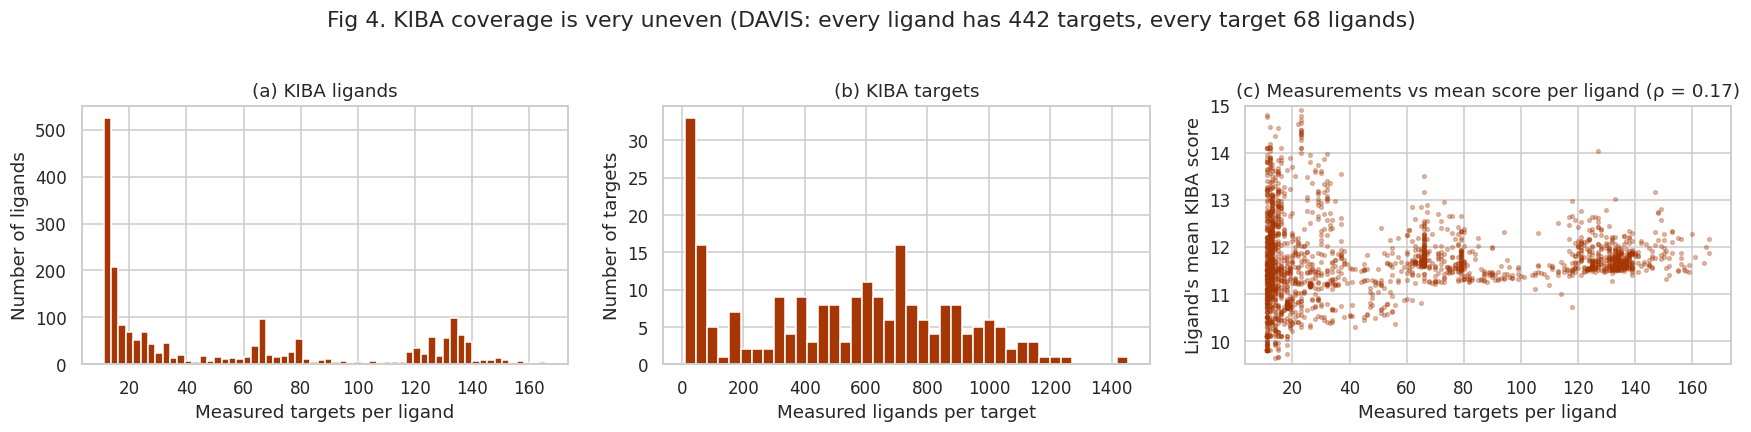

,KIBA ligands,KIBA targets
min,11.0,11.0
25%,14.0,173.0
50%,30.0,567.0
75%,96.0,774.0
max,166.0,1452.0


Spearman ρ between a ligand's number of measurements and its mean score: 0.17
Mean score, ligands with ≤ 20 measurements: 11.56 (n = 866);  ≥ 100: 11.77 (n = 520)


,KIBA
Ligands with ≤ 20 measured targets,41.0%
Ligand pairs sharing 0 targets,8.1%
Ligand pairs sharing ≥ 5 targets,62.1%
Ligand pairs sharing ≥ 20 targets,24.0%
Median shared targets per ligand pair,7
Ligands with no other ligand sharing ≥ 5 targets,0


In [12]:
obs_k = M_k.notna().values.astype(np.float32)
per_lig_k = obs_k.sum(1); per_tgt_k = obs_k.sum(0)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(per_lig_k, bins=60, color="#a63603")
axes[0].set(xlabel="Measured targets per ligand", ylabel="Number of ligands", title="(a) KIBA ligands")
axes[1].hist(per_tgt_k, bins=40, color="#a63603")
axes[1].set(xlabel="Measured ligands per target", ylabel="Number of targets", title="(b) KIBA targets")
mean_lig_k = np.nanmean(M_k.values, axis=1)
rho_mnar = stats.spearmanr(per_lig_k, mean_lig_k).statistic
axes[2].scatter(per_lig_k, mean_lig_k, s=6, alpha=0.3, color="#a63603")
axes[2].set(xlabel="Measured targets per ligand", ylabel="Ligand's mean KIBA score", title=f"(c) Measurements vs mean score per ligand (ρ = {rho_mnar:.2f})")
axes[2].set_ylim(9.5, 15)
fig.suptitle("Fig 4. KIBA coverage is very uneven (DAVIS: every ligand has 442 targets, every target 68 ligands)", y=1.03)
fig.tight_layout(); fig.savefig("figures/fig4_kiba_coverage.png"); plt.show()

overlap = obs_k @ obs_k.T
iu = np.triu_indices_from(overlap, k=1)
ov = overlap[iu]
cov_table = pd.DataFrame({
    "KIBA ligands": pd.Series(per_lig_k).describe()[["min", "25%", "50%", "75%", "max"]],
    "KIBA targets": pd.Series(per_tgt_k).describe()[["min", "25%", "50%", "75%", "max"]],
}).round(0)
display(cov_table)
print(f"Spearman ρ between a ligand's number of measurements and its mean score: {rho_mnar:.2f}")
few, many = per_lig_k <= 20, per_lig_k >= 100
print(f"Mean score, ligands with ≤ 20 measurements: {mean_lig_k[few].mean():.2f} (n = {few.sum()});  ≥ 100: {mean_lig_k[many].mean():.2f} (n = {many.sum()})")
nb = pd.Series({
    "Ligands with ≤ 20 measured targets": f"{(per_lig_k <= 20).mean():.1%}",
    "Ligand pairs sharing 0 targets": f"{(ov == 0).mean():.1%}",
    "Ligand pairs sharing ≥ 5 targets": f"{(ov >= 5).mean():.1%}",
    "Ligand pairs sharing ≥ 20 targets": f"{(ov >= 20).mean():.1%}",
    "Median shared targets per ligand pair": f"{np.median(ov):.0f}",
    "Ligands with no other ligand sharing ≥ 5 targets": int((((overlap >= 5).sum(1) - 1) == 0).sum()),
}, name="KIBA")
nb.to_csv("results/table7_kiba_neighbours.csv")
display(nb.to_frame())

**Neighbour availability.** KIBA has already been filtered so that every ligand and target has at least 11 measurements, but coverage is still very uneven. The median ligand has 30 measured targets (out of 229) and 41.0% of ligands have 20 or fewer. Targets range from 11 to 1,452 measured ligands. For a pair of ligands, the median number of shared targets is only 7. 8.1% of ligand pairs share none at all, and only 24.0% share 20 or more. Any similarity between two KIBA ligands is therefore estimated from very few common targets and will be noisy, which is the key difficulty for neighbour-based CF on KIBA. DAVIS has the opposite situation: every ligand pair shares all 442 targets. Fig 4c shows a weak positive link between how often a ligand was measured and its mean score (ρ = 0.17), plus a clear split between lightly measured ligands, whose means range widely, and heavily screened panel ligands, whose means cluster tightly around 11.7.

#### (B) Ligand selectivity in DAVIS

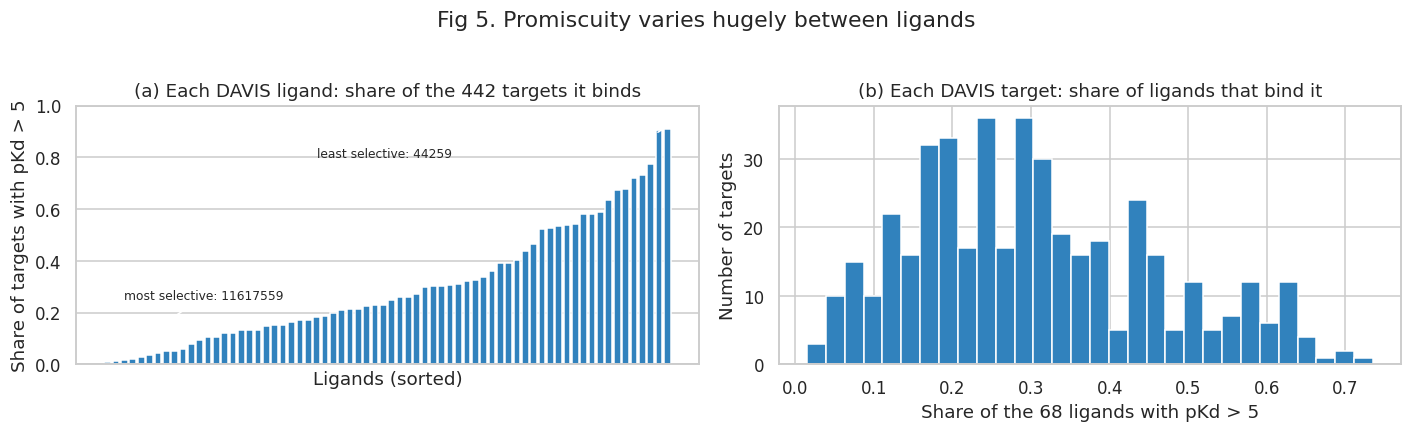

Ligand binding share: min 0.9% (11617559), median 24.0%, max 91.0% (44259)
Ligands binding < 10% of targets: 12 of 68;  binding > 50%: 16
Molecular formula of 44259: C28H26N4O3 (staurosporine is C28H26N4O3)
Targets bound by no ligand: 0;  median target binding share: 27.9%


In [14]:
!pip install -q rdkit
sel = (M_d > 5).mean(1).sort_values()
tgt_hit = (M_d > 5).mean(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(range(len(sel)), sel.values, color="#3182bd")
axes[0].set(xlabel="Ligands (sorted)", ylabel="Share of targets with pKd > 5", title="(a) Each DAVIS ligand: share of the 442 targets it binds")
axes[0].set_xticks([])
axes[0].annotate(f"most selective: {sel.index[0]}", (0, sel.values[0]), xytext=(2, 0.25), fontsize=8, arrowprops=dict(arrowstyle="->"))
axes[0].annotate(f"least selective: {sel.index[-1]}", (len(sel) - 1, sel.values[-1]), xytext=(25, 0.8), fontsize=8, arrowprops=dict(arrowstyle="->"))
axes[0].set_ylim(0, 1)
axes[1].hist(tgt_hit, bins=30, color="#3182bd")
axes[1].set(xlabel="Share of the 68 ligands with pKd > 5", ylabel="Number of targets", title="(b) Each DAVIS target: share of ligands that bind it")
fig.suptitle("Fig 5. Promiscuity varies hugely between ligands", y=1.03)
fig.tight_layout(); fig.savefig("figures/fig5_davis_selectivity.png"); plt.show()
print(f"Ligand binding share: min {sel.min():.1%} ({sel.index[0]}), median {sel.median():.1%}, max {sel.max():.1%} ({sel.index[-1]})")
print(f"Ligands binding < 10% of targets: {(sel < .10).sum()} of {len(sel)};  binding > 50%: {(sel > .5).sum()}")
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
from rdkit import Chem as _Chem
print(f"Molecular formula of {sel.index[-1]}: {CalcMolFormula(_Chem.MolFromSmiles(lig_d[sel.index[-1]]))} (staurosporine is C28H26N4O3)")
print(f"Targets bound by no ligand: {(tgt_hit == 0).sum()};  median target binding share: {tgt_hit.median():.1%}")

**Selectivity.** DAVIS ligands range from binding 0.9% of targets (ligand 11617559) to 91.0% (ligand 44259, whose formula C28H26N4O3 matches staurosporine, a well-known non-selective kinase inhibitor). 12 of the 68 ligands bind fewer than 10% of targets and 16 bind more than half. Every target is bound by at least one ligand, with a median target bound by 27.9% of ligands. This matters for recommendation. For a promiscuous ligand almost every target scores well, so ranking is hard and "best target" is close to a tie. For a highly selective ligand, almost every target sits at pKd = 5 and there is a single right answer. The three DAVIS case-study ligands in the brief can be checked against this spectrum.

#### (C) How much is ligand effect, target effect, or interaction?

We fit four simple descriptive models on all observed entries and report R² (share of score variance explained). The additive model `score ≈ μ + b_ligand + b_target` is fitted by alternating averages, using observed entries only, so it works on sparse KIBA too. This is purely descriptive and is not used for evaluation. Whatever the additive model cannot explain is the ligand–target *interaction*, the part only a personalised method such as CF can capture.

In [15]:
def r2_decomposition(df, lig="ligand_id", tgt="target_id", iters=30):
    y = df["score"].values; mu = y.mean(); sst = ((y - mu) ** 2).sum()
    r2 = lambda pred: 1 - ((y - pred) ** 2).sum() / sst
    lm = df.groupby(lig)["score"].transform("mean").values
    tm = df.groupby(tgt)["score"].transform("mean").values
    bl = pd.Series(0.0, index=df[lig].unique()); bt = pd.Series(0.0, index=df[tgt].unique())
    for _ in range(iters):
        bt = (df["score"] - mu - df[lig].map(bl)).groupby(df[tgt]).mean()
        bl = (df["score"] - mu - df[tgt].map(bt)).groupby(df[lig]).mean()
    add = mu + df[lig].map(bl).values + df[tgt].map(bt).values
    return pd.Series({"Ligand mean only": r2(lm), "Target mean only": r2(tm),
                      "Ligand + target (additive)": r2(add), "Unexplained (interaction + noise)": 1 - r2(add)})

r2_tab = pd.DataFrame({"DAVIS": r2_decomposition(davis_c), "KIBA": r2_decomposition(kiba_c)}).round(3)
r2_tab.to_csv("results/table8_variance_decomposition.csv")
display(r2_tab)

,DAVIS,KIBA
Ligand mean only,0.226,0.420
Target mean only,0.126,0.141
Ligand + target (additive),0.353,0.521
Unexplained (interaction + noise),0.647,0.479


**Variance decomposition.** Knowing only the ligand explains 22.6% of score variance in DAVIS and 42.0% in KIBA. Adding the target as an additive effect raises this to 35.3% and 52.1%. The rest (64.7% in DAVIS and 47.9% in KIBA) is ligand–target interaction plus noise, which is exactly what a mean baseline cannot capture and CF could. KIBA is more "ligand-driven": a ligand's average score already tells you a lot, so a ligand-mean baseline will be strong there and CF has less room to improve. DAVIS has more interaction structure for CF to exploit, but much of it is the censored/non-censored pattern.

#### (D) Low-rank structure of DAVIS

DAVIS is complete, so we can take an SVD of the double-centred pKd matrix (ligand and target means removed) and see how many latent factors carry the interaction signal. KIBA cannot be decomposed this way without imputing three quarters of the matrix, and imputing would invent data.

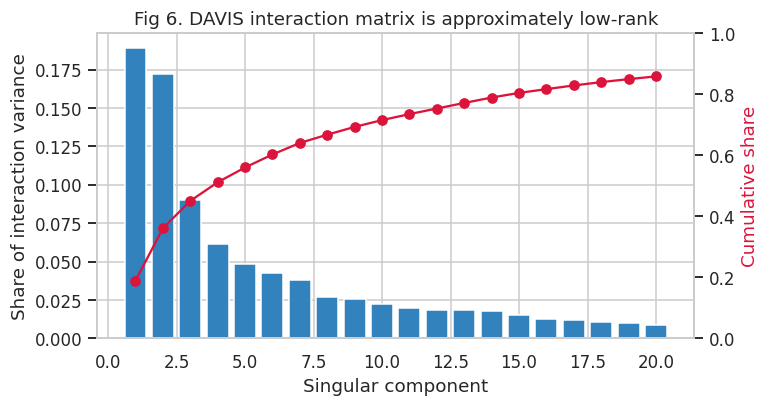

{'top 1': '18.9%', 'top 3': '45.1%', 'top 5': '56.0%', 'top 10': '71.6%', 'top 20': '85.9%'}


In [16]:
X = M_d.values
Xc = X - X.mean(1, keepdims=True) - X.mean(0, keepdims=True) + X.mean()
s = np.linalg.svd(Xc, compute_uv=False)
ev = s ** 2 / (s ** 2).sum(); cum = np.cumsum(ev)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(np.arange(1, 21), ev[:20], color="#3182bd", label="per component")
ax2 = ax.twinx(); ax2.plot(np.arange(1, 21), cum[:20], "o-", color="crimson", label="cumulative"); ax2.set_ylim(0, 1)
ax2.grid(False)
ax.set(xlabel="Singular component", ylabel="Share of interaction variance", title="Fig 6. DAVIS interaction matrix is approximately low-rank")
ax2.set_ylabel("Cumulative share", color="crimson")
fig.savefig("figures/fig6_davis_svd.png"); plt.show()
print({f"top {k}": f"{cum[k-1]:.1%}" for k in [1, 3, 5, 10, 20]})

**Low rank.** The DAVIS interaction matrix (after removing ligand and target means) has 68 possible components, but the top 3 explain 45.1% of its variance, the top 10 explain 71.6% and the top 20 explain 85.9%. Binding profiles are therefore driven by a small number of latent factors, plausibly kinase families and inhibitor chemotypes. This supports matrix factorisation for Task 2 and suggests a latent dimension around 5–20 as a sensible search range on the validation set.

#### (E) Does structural similarity predict binding similarity?

For ligands we compare chemical similarity (Tanimoto on Morgan fingerprints, radius 2, 2048 bits, via RDKit) with binding-profile similarity (Pearson correlation of scores over the targets both ligands were measured on, needing at least 10 shared targets). For targets we compare sequence similarity (cosine of 3-mer amino-acid composition vectors) with binding-profile similarity over shared ligands. We use the deduplicated strings so that identical inputs are not compared with themselves.

*Code reuse:* Morgan fingerprints are generated with RDKit's standard `AllChem.GetMorganFingerprintAsBitVect` call. The masked pairwise Pearson formula is our own vectorised version of the textbook formula.

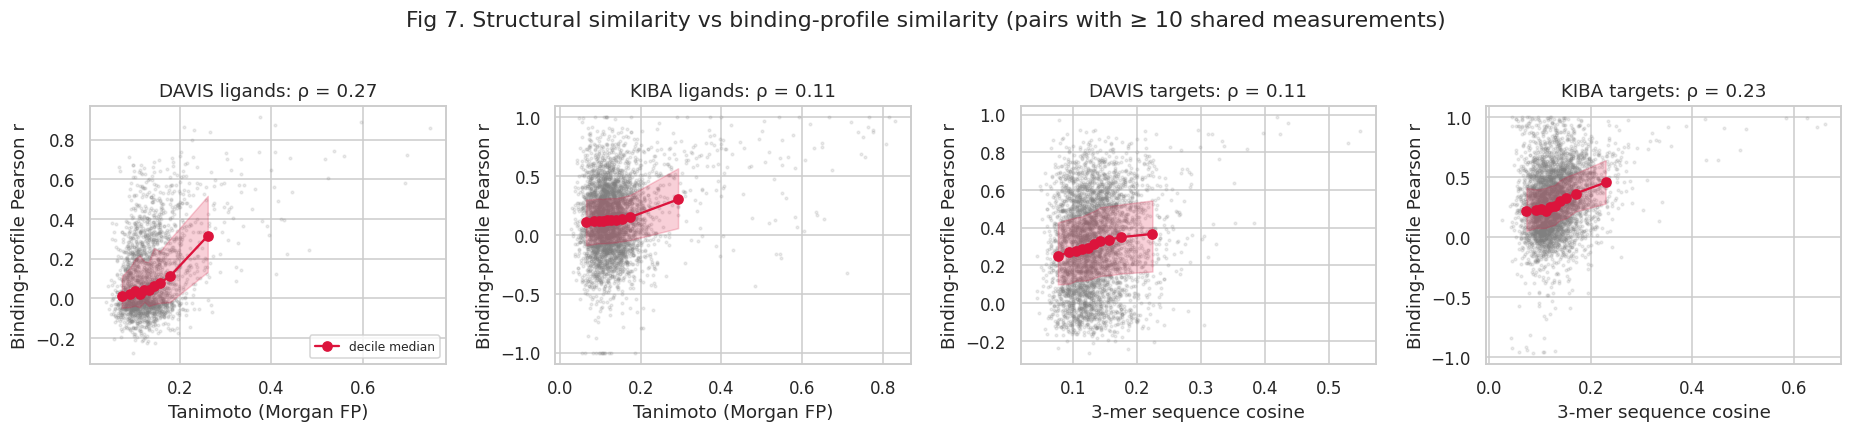

,dataset,entity,pairs compared,Spearman ρ
0,DAVIS,ligands,2278,0.270
1,KIBA,ligands,820288,0.114
2,DAVIS,targets,71631,0.114
3,KIBA,targets,17086,0.231


In [17]:
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
RDLogger.DisableLog("rdApp.*")

def morgan_matrix(smiles_list):
    F = np.zeros((len(smiles_list), 2048), dtype=np.float32)
    for i, s in enumerate(smiles_list):
        fp = AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, nBits=2048)
        F[i, list(fp.GetOnBits())] = 1
    inter = F @ F.T; cnt = F.sum(1)
    return inter / (cnt[:, None] + cnt[None, :] - inter)

def kmer_cosine(seqs, k=3):
    from sklearn.feature_extraction.text import CountVectorizer
    V = CountVectorizer(analyzer="char", ngram_range=(k, k), lowercase=False).fit_transform(seqs).astype(np.float32)
    V = V.multiply(1 / np.sqrt(V.multiply(V).sum(1))).tocsr()
    return (V @ V.T).toarray()

def masked_pearson(Mat):
    """Pearson correlation between rows of Mat using only co-observed columns. Returns (corr, n_shared)."""
    Mat = Mat - np.nanmean(Mat, axis=1, keepdims=True)  # shifting a row does not change Pearson r, but avoids round-off
    O = (~np.isnan(Mat)).astype(np.float64); Xf = np.nan_to_num(Mat)
    n = O @ O.T; sx = Xf @ O.T; sy = sx.T; sxx = (Xf ** 2) @ O.T; syy = sxx.T; sxy = Xf @ Xf.T
    num = n * sxy - sx * sy
    den = np.sqrt(np.clip(n * sxx - sx ** 2, 0, None) * np.clip(n * syy - sy ** 2, 0, None))
    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.where(den > 1e-9 * n ** 2, num / den, np.nan)  # undefined if either profile is constant on shared columns
    return np.clip(C, -1, 1), n

def sim_vs_profile(dd, struct_fn, entity, min_shared=10):
    key, other = ("smiles", "sequence") if entity == "ligand" else ("sequence", "smiles")
    Mat = dd.pivot(index=key, columns=other, values="score")
    S = struct_fn(list(Mat.index))
    C, n = masked_pearson(Mat.values)
    iu = np.triu_indices(len(Mat), 1)
    ok = (n[iu] >= min_shared) & np.isfinite(C[iu])
    return S[iu][ok], C[iu][ok]

res = {}
res[("DAVIS", "ligands")] = sim_vs_profile(davis_dd, morgan_matrix, "ligand")
res[("KIBA", "ligands")] = sim_vs_profile(kiba_dd, morgan_matrix, "ligand")
res[("DAVIS", "targets")] = sim_vs_profile(davis_dd, kmer_cosine, "target")
res[("KIBA", "targets")] = sim_vs_profile(kiba_dd, kmer_cosine, "target")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
rows = []
for ax, ((ds, ent), (sx, cy)) in zip(axes, res.items()):
    bins = np.quantile(sx, np.linspace(0, 1, 11))
    idx = np.clip(np.digitize(sx, bins[1:-1]), 0, 9)
    mids = [sx[idx == b].mean() for b in range(10)]
    med = [np.median(cy[idx == b]) for b in range(10)]
    q1 = [np.quantile(cy[idx == b], .25) for b in range(10)]; q3 = [np.quantile(cy[idx == b], .75) for b in range(10)]
    sub = rng.choice(len(sx), min(4000, len(sx)), replace=False)
    ax.scatter(sx[sub], cy[sub], s=3, alpha=0.15, color="grey")
    ax.plot(mids, med, "o-", color="crimson", label="decile median"); ax.fill_between(mids, q1, q3, color="crimson", alpha=0.2)
    rho = stats.spearmanr(sx, cy).statistic
    rows.append({"dataset": ds, "entity": ent, "pairs compared": len(sx), "Spearman ρ": round(rho, 3)})
    xl = "Tanimoto (Morgan FP)" if ent == "ligands" else "3-mer sequence cosine"
    ax.set(xlabel=xl, ylabel="Binding-profile Pearson r", title=f"{ds} {ent}: ρ = {rho:.2f}")
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Fig 7. Structural similarity vs binding-profile similarity (pairs with ≥ 10 shared measurements)", y=1.03)
fig.tight_layout(); fig.savefig("figures/fig7_structure_vs_profile.png"); plt.show()
sim_table = pd.DataFrame(rows); sim_table.to_csv("results/table9_structure_vs_profile.csv", index=False)
display(sim_table)

**Structure vs binding.** All four correlations are positive but weak (ρ = 0.11 to 0.27). Chemically similar DAVIS ligands bind similar target sets (ρ = 0.27), and the trend is steepest in the top decile of Tanimoto similarity. Similar KIBA target sequences have similar ligand profiles (ρ = 0.23). The KIBA ligand signal is weakest (ρ = 0.11), partly because profiles are compared over few shared targets. DAVIS targets are weak (ρ = 0.11) because 3-mer composition over a full-length sequence mostly captures general protein composition rather than the binding pocket, and because mutants share sequences.

This is the motivating evidence for Task 3. Sequence similarity carries a real but modest signal about how a target binds, so a cold-target model can use it to replace missing measurements, but simple whole-sequence features will not be enough. Better protein representations, such as pocket- or domain-focused features or learned embeddings, are likely needed.

#### (F) Overlap and agreement between DAVIS and KIBA

Shared ligands (identical SMILES): 9
Shared targets (identical sequence): 179
Pairs measured in both datasets: 1043
Spearman ρ between DAVIS pKd and KIBA score on shared pairs: 0.69
KIBA score where DAVIS is censored (n = 571): mean 11.59, median 11.50;  where DAVIS is fully measured (n = 457): mean 12.77


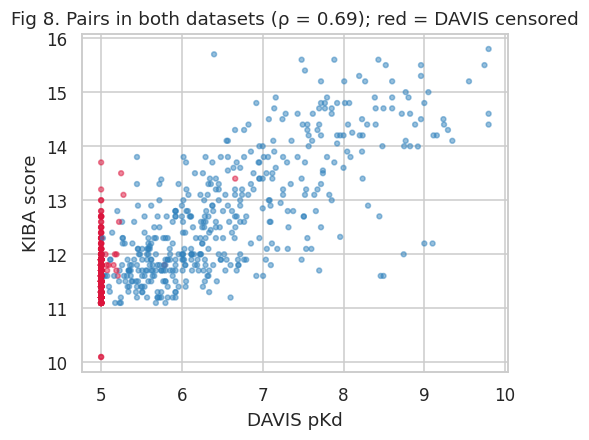

In [18]:
shared_lig = set(davis_dd["smiles"]) & set(kiba_dd["smiles"])
shared_seq = set(davis_dd["sequence"]) & set(kiba_dd["sequence"])
both = davis_dd.merge(kiba_dd, on=["smiles", "sequence"], suffixes=("_davis", "_kiba"))
print(f"Shared ligands (identical SMILES): {len(shared_lig)}")
print(f"Shared targets (identical sequence): {len(shared_seq)}")
print(f"Pairs measured in both datasets: {len(both)}")
if len(both) >= 10:
    rho = stats.spearmanr(both["score_davis"], both["score_kiba"]).statistic
    print(f"Spearman ρ between DAVIS pKd and KIBA score on shared pairs: {rho:.2f}")
    cen = both["censored_frac"] == 1
    print(f"KIBA score where DAVIS is censored (n = {cen.sum()}): mean {both.loc[cen, 'score_kiba'].mean():.2f}, "
          f"median {both.loc[cen, 'score_kiba'].median():.2f};  where DAVIS is fully measured (n = {(both['censored_frac'] == 0).sum()}): "
          f"mean {both.loc[both['censored_frac'] == 0, 'score_kiba'].mean():.2f}")
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.scatter(both["score_davis"], both["score_kiba"], s=10, alpha=0.5, c=np.where(both["censored_frac"] > 0, "crimson", "#3182bd"))
    ax.set(xlabel="DAVIS pKd", ylabel="KIBA score", title=f"Fig 8. Pairs in both datasets (ρ = {rho:.2f}); red = DAVIS censored")
    fig.savefig("figures/fig8_davis_kiba_overlap.png"); plt.show()

**Overlap.** The two datasets share only 9 identical ligands but 179 identical target sequences, and 1,043 pairs are measured in both. Where both exist, the scores agree well in rank (Spearman ρ = 0.69, Fig 8), which supports treating both as measures of the same underlying affinity. The censored DAVIS pairs are informative here. Where DAVIS says "pKd = 5 (no binding detected)", KIBA gives a mean of 11.59, close to its own spike at ~11.2, while fully measured DAVIS pairs average 12.77 in KIBA. KIBA's dense band around 11.1–11.9 therefore behaves much like DAVIS's censored floor, a weak-or-inactive region rather than precise affinities. This is our interpretation of the overlap, not something documented with the dataset.

## 4. Summary table: key differences between DAVIS and KIBA

In [19]:
summary = pd.DataFrame({
    "DAVIS": {
        "Size (dedup ligands × targets)": f"{davis_dd['smiles'].nunique()} × {davis_dd['sequence'].nunique()}",
        "Observed pairs (dedup)": f"{len(davis_dd):,}",
        "Sparsity": "0% (complete)",
        "Score": "pKd from a single assay type (Kd)",
        "Typical score": f"median {d_all.median():.2f}, mean {d_all.mean():.2f}",
        "Main abnormality": f"{davis_c['censored'].mean():.1%} of pairs at screening limit pKd = 5",
        "Variance explained by ligand + target means": f"{r2_tab.loc['Ligand + target (additive)', 'DAVIS']:.1%}",
        "Duplicate issue": f"{len(g_dp)} sequence groups merge {sum(len(g) for g in g_dp)} target IDs (mutants, domains)",
    },
    "KIBA": {
        "Size (dedup ligands × targets)": f"{kiba_dd['smiles'].nunique()} × {kiba_dd['sequence'].nunique()}",
        "Observed pairs (dedup)": f"{len(kiba_dd):,}",
        "Sparsity": count_table[("KIBA", "Deduplicated (SMILES, sequence)")]["Sparsity (missing / all positions)"],
        "Score": "Composite of Ki, Kd, IC50",
        "Typical score": f"median {k_all.median():.2f}, mean {k_all.mean():.2f}",
        "Main abnormality": f"{n_low} extreme low values incl. one 0.0; missingness is not random",
        "Variance explained by ligand + target means": f"{r2_tab.loc['Ligand + target (additive)', 'KIBA']:.1%}",
        "Duplicate issue": f"{len(g_kl)} SMILES groups merge {sum(len(g) for g in g_kl)} ligand IDs (stereoisomers)",
    },
})
summary.to_csv("results/table10_davis_vs_kiba.csv")
display(summary)

,DAVIS,KIBA
Size (dedup ligands × targets),68 × 379,2068 × 229
Observed pairs (dedup),"25,772","117,657"
Sparsity,0% (complete),75.16%
Score,pKd from a single assay type (Kd),"Composite of Ki, Kd, IC50"
Typical score,"median 5.00, mean 5.45","median 11.50, mean 11.72"
Main abnormality,69.6% of pairs at screening limit pKd = 5,20 extreme low values incl. one 0.0; missingness is not ...
Variance explained by ligand + target means,35.3%,52.1%
Duplicate issue,"18 sequence groups merge 81 target IDs (mutants, domains)",32 SMILES groups merge 75 ligand IDs (stereoisomers)


## 5. Key findings and what they mean for Tasks 2 and 3

1. **DAVIS is complete but heavily censored.** 69.6% of pairs sit at the pKd = 5 screening limit; blanking them (Fig 1b) leaves only a third of the matrix as real measurements. They are kept and flagged. A model that predicts "5" everywhere already scores a low MSE, so Task 2 must compare against a baseline and report ranking metrics.
2. **KIBA is large but 75.5% missing, and missingness is structured by screening panels** (Fig 2a). Ligand pairs share a median of only 7 targets, so neighbour similarities are noisy and many predictions will fall back to means. Missing is never treated as non-binding.
3. **Deduplication depends on the input.** At ID level there are no duplicates. At string level, DAVIS mutants collapse (442 to 379 targets) and KIBA stereoisomers collapse (2,111 to 2,068 ligands), and merged scores can differ by up to 4.75 pKd units. We keep both versions and use the one that matches each task's input.
4. **Ligand identity explains a lot.** It accounts for 22.6% (DAVIS) and 42.0% (KIBA) of variance alone, and ligand + target means explain 35.3% and 52.1%. CF only adds value through the remaining interaction, which is larger in DAVIS. The dense-core view (Fig 2b) shows that interaction directly, as blocks that cut across the general ligand and target effects.
5. **DAVIS interactions are low-rank** (top 10 components = 71.6%, Fig 6), which supports matrix factorisation.
6. **Structural similarity weakly predicts binding similarity** (ρ = 0.11 to 0.27, Fig 7), which is the starting point for cold-target prediction in Task 3.

**Figure index.** Fig 1 DAVIS heatmaps (full, binders only) · Fig 2 KIBA heatmaps (full, dense core) · Fig 3 score distributions · Fig 4 KIBA coverage · Fig 5 DAVIS selectivity · Fig 6 DAVIS SVD · Fig 7 structure vs binding profile · Fig 8 DAVIS-KIBA overlap.

In [20]:
#splitting of dataset
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import os

SEED = 42

def make_cf_split(df, seed=SEED):
    """
    70/15/15 pair-level split.
    Every ligand and target must occur in training.
    """
    df = df[["ligand_id", "target_id", "score"]].copy()
    df = df.dropna(subset=["score"]).reset_index(drop=True)

    # Each ligand-target pair must be unique
    assert not df.duplicated(["ligand_id", "target_id"]).any()

    all_ligands = set(df["ligand_id"])
    all_targets = set(df["target_id"])

    for attempt in range(1000):
        random_state = seed + attempt

        train, remaining = train_test_split(
            df,
            test_size=0.30,
            random_state=random_state
        )

        val, test = train_test_split(
            remaining,
            test_size=0.50,
            random_state=random_state
        )

        train_ligands = set(train["ligand_id"])
        train_targets = set(train["target_id"])

        # All entities must have training observations
        if (all_ligands.issubset(train_ligands)
                and all_targets.issubset(train_targets)):
            break
    else:
        raise ValueError("Could not find a valid split.")

    # Verify there is no pair overlap
    train_pairs = set(zip(train.ligand_id, train.target_id))
    val_pairs = set(zip(val.ligand_id, val.target_id))
    test_pairs = set(zip(test.ligand_id, test.target_id))

    assert train_pairs.isdisjoint(val_pairs)
    assert train_pairs.isdisjoint(test_pairs)
    assert val_pairs.isdisjoint(test_pairs)

    # Verify no cold-start entities
    for split in [val, test]:
        assert set(split.ligand_id).issubset(train_ligands)
        assert set(split.target_id).issubset(train_targets)

    return train, val, test


davis_train, davis_val, davis_test = make_cf_split(davis_c)
kiba_train, kiba_val, kiba_test = make_cf_split(kiba_c)

def split_summary(name, train, val, test):
    return pd.DataFrame({
        "Dataset": [name] * 3,
        "Partition": ["Train", "Validation", "Test"],
        "Observations": [len(train), len(val), len(test)],
        "Percentage": [
            len(train) / (len(train) + len(val) + len(test)) * 100,
            len(val) / (len(train) + len(val) + len(test)) * 100,
            len(test) / (len(train) + len(val) + len(test)) * 100
        ]
    })

split_results = pd.concat([
    split_summary("DAVIS", davis_train, davis_val, davis_test),
    split_summary("KIBA", kiba_train, kiba_val, kiba_test)
])

display(split_results.round(2))



,Dataset,Partition,Observations,Percentage
0,DAVIS,Train,21039,70.0
1,DAVIS,Validation,4508,15.0
2,DAVIS,Test,4509,15.0
0,KIBA,Train,82777,70.0
1,KIBA,Validation,17738,15.0
2,KIBA,Test,17739,15.0


##2.2 Recommending a Drug to a Given Target with collaborative filtering


In [21]:
from itertools import product

class BiasedMatrixFactorization:

    def __init__(self, n_factors=16, learning_rate=0.005,
                 reg=0.01, epochs=100, seed=42):

        self.n_factors = n_factors
        self.lr = learning_rate
        self.reg = reg
        self.epochs = epochs
        self.seed = seed

    def fit(self, train_df, verbose=False):

        rng = np.random.default_rng(self.seed)

        # Map ligand and target IDs to integer indices
        self.ligands = sorted(train_df["ligand_id"].unique())
        self.targets = sorted(train_df["target_id"].unique())

        self.lig_to_idx = {x: i for i, x in enumerate(self.ligands)}
        self.tar_to_idx = {x: i for i, x in enumerate(self.targets)}

        u = train_df["ligand_id"].map(self.lig_to_idx).to_numpy()
        i = train_df["target_id"].map(self.tar_to_idx).to_numpy()
        r = train_df["score"].to_numpy(dtype=np.float64)

        self.global_mean = r.mean()

        n_users = len(self.ligands)
        n_items = len(self.targets)

        # Initialise latent factors and biases
        self.P = rng.normal(0, 0.05, (n_users, self.n_factors))
        self.Q = rng.normal(0, 0.05, (n_items, self.n_factors))

        self.bu = np.zeros(n_users)
        self.bi = np.zeros(n_items)

        self.training_history = []

        # Mini-batch SGD
        batch_size = 4096

        for epoch in range(self.epochs):

            order = rng.permutation(len(r))

            for start in range(0, len(r), batch_size):

                batch = order[start:start + batch_size]

                ub = u[batch]
                ib = i[batch]
                rb = r[batch]

                pu = self.P[ub].copy()
                qi = self.Q[ib].copy()

                pred = (
                    self.global_mean
                    + self.bu[ub]
                    + self.bi[ib]
                    + np.sum(pu * qi, axis=1)
                )

                error = rb - pred

                # Bias updates
                np.add.at(
                    self.bu, ub,
                    self.lr * (error - self.reg * self.bu[ub])
                )

                np.add.at(
                    self.bi, ib,
                    self.lr * (error - self.reg * self.bi[ib])
                )

                # Latent factor updates
                grad_p = (
                    error[:, None] * qi
                    - self.reg * pu
                )

                grad_q = (
                    error[:, None] * pu
                    - self.reg * qi
                )

                np.add.at(self.P, ub, self.lr * grad_p)
                np.add.at(self.Q, ib, self.lr * grad_q)

            # Record training MSE
            train_pred = self.predict(
                train_df["ligand_id"],
                train_df["target_id"]
            )

            train_mse = np.mean(
                (train_df["score"].to_numpy() - train_pred) ** 2
            )

            self.training_history.append(train_mse)

            if verbose and (epoch + 1) % 20 == 0:
                print(
                    f"Epoch {epoch + 1}/{self.epochs} "
                    f"| Training MSE: {train_mse:.4f}"
                )

        return self

    def predict(self, ligand_ids, target_ids):

        ligand_idx = np.array([
            self.lig_to_idx[x] for x in ligand_ids
        ])

        target_idx = np.array([
            self.tar_to_idx[x] for x in target_ids
        ])

        return (
            self.global_mean
            + self.bu[ligand_idx]
            + self.bi[target_idx]
            + np.sum(
                self.P[ligand_idx] * self.Q[target_idx],
                axis=1
            )
        )

In [22]:
#test model on davis data
davis_model = BiasedMatrixFactorization(
    n_factors=16,
    learning_rate=0.005,
    reg=0.01,
    epochs=100,
    seed=42
)

davis_model.fit(davis_train, verbose=True)

davis_val_pred = davis_model.predict(
    davis_val["ligand_id"],
    davis_val["target_id"]
)

davis_val_mse = np.mean(
    (davis_val["score"].to_numpy() - davis_val_pred) ** 2
)

print("DAVIS validation MSE:", round(davis_val_mse, 4))

Epoch 20/100 | Training MSE: 0.4114
Epoch 40/100 | Training MSE: 0.1917
Epoch 60/100 | Training MSE: 0.1295
Epoch 80/100 | Training MSE: 0.1052
Epoch 100/100 | Training MSE: 0.0935
DAVIS validation MSE: 0.276


###Hyperparameter tuning


In [23]:
def tune_cf_model(train_df, val_df, dataset_name):

    param_grid = {
        "n_factors": [8, 16, 32],
        "learning_rate": [0.005, 0.01],
        "reg": [0.01, 0.1]
    }

    results = []

    configs = list(product(
        param_grid["n_factors"],
        param_grid["learning_rate"],
        param_grid["reg"]
    ))

    for count, (factors, lr, reg) in enumerate(configs, 1):

        print(
            f"{dataset_name}: Configuration "
            f"{count}/{len(configs)}"
        )

        model = BiasedMatrixFactorization(
            n_factors=factors,
            learning_rate=lr,
            reg=reg,
            epochs=100,
            seed=42
        )

        model.fit(train_df)

        predictions = model.predict(
            val_df["ligand_id"],
            val_df["target_id"]
        )

        mse = np.mean(
            (val_df["score"].to_numpy() - predictions) ** 2
        )

        results.append({
            "n_factors": factors,
            "learning_rate": lr,
            "regularization": reg,
            "validation_MSE": mse
        })

    results_df = pd.DataFrame(results).sort_values(
        "validation_MSE"
    ).reset_index(drop=True)

    best = results_df.iloc[0]

    best_model = BiasedMatrixFactorization(
        n_factors=int(best["n_factors"]),
        learning_rate=float(best["learning_rate"]),
        reg=float(best["regularization"]),
        epochs=100,
        seed=42
    )

    best_model.fit(train_df)

    print(f"\nBest {dataset_name} configuration:")
    display(results_df.head())

    return best_model, results_df

In [24]:
best_davis_model, davis_tuning = tune_cf_model(
    davis_train,
    davis_val,
    "DAVIS"
)

best_kiba_model, kiba_tuning = tune_cf_model(
    kiba_train,
    kiba_val,
    "KIBA"
)

davis_tuning.to_csv(
    "results/davis_cf_tuning.csv", index=False
)

kiba_tuning.to_csv(
    "results/kiba_cf_tuning.csv", index=False
)

DAVIS: Configuration 1/12
DAVIS: Configuration 2/12
DAVIS: Configuration 3/12
DAVIS: Configuration 4/12
DAVIS: Configuration 5/12
DAVIS: Configuration 6/12
DAVIS: Configuration 7/12
DAVIS: Configuration 8/12
DAVIS: Configuration 9/12
DAVIS: Configuration 10/12
DAVIS: Configuration 11/12
DAVIS: Configuration 12/12

Best DAVIS configuration:


,n_factors,learning_rate,regularization,validation_MSE
0,32,0.005,0.01,0.258968
1,32,0.010,0.01,0.261817
2,16,0.005,0.01,0.276044
3,16,0.010,0.01,0.287210
4,8,0.005,0.01,0.293074


KIBA: Configuration 1/12
KIBA: Configuration 2/12
KIBA: Configuration 3/12
KIBA: Configuration 4/12
KIBA: Configuration 5/12
KIBA: Configuration 6/12
KIBA: Configuration 7/12
KIBA: Configuration 8/12
KIBA: Configuration 9/12
KIBA: Configuration 10/12
KIBA: Configuration 11/12
KIBA: Configuration 12/12

Best KIBA configuration:


,n_factors,learning_rate,regularization,validation_MSE
0,32,0.005,0.01,0.207204
1,32,0.010,0.01,0.212289
2,16,0.005,0.01,0.219134
3,16,0.010,0.01,0.221449
4,8,0.005,0.01,0.232301


## Evaluation of metrics

In [25]:
from sklearn.metrics import mean_squared_error

def calculate_ci(y_true, y_pred, max_pairs=1_000_000, seed=42):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    n = len(y_true)

    if n < 2:
        return np.nan

    rng = np.random.default_rng(seed)

    # Randomly sample pairs of observations
    n_pairs = min(max_pairs, n * (n - 1) // 2)

    a = rng.integers(0, n, size=n_pairs)
    b = rng.integers(0, n, size=n_pairs)

    valid = a != b
    a = a[valid]
    b = b[valid]

    true_diff = y_true[a] - y_true[b]
    pred_diff = y_pred[a] - y_pred[b]

    # Exclude pairs tied in true scores
    valid = true_diff != 0

    true_diff = true_diff[valid]
    pred_diff = pred_diff[valid]

    if len(true_diff) == 0:
        return np.nan

    concordant = true_diff * pred_diff > 0
    predicted_ties = pred_diff == 0

    ci = (
        concordant.sum() + 0.5 * predicted_ties.sum()
    ) / len(true_diff)

    return ci


def calculate_hit_rates(test_df, predictions):

    result = test_df[
        ["ligand_id", "target_id", "score"]
    ].copy()

    result["predicted_score"] = predictions

    hits_1 = []
    hits_5 = []

    for ligand, group in result.groupby("ligand_id"):

        # Highest true score among held-out observed candidates
        best_score = group["score"].max()

        # Allow multiple true best targets in case of ties
        true_best = set(
            group.loc[
                group["score"] == best_score,
                "target_id"
            ]
        )

        ranked = group.sort_values(
            "predicted_score",
            ascending=False
        )

        top_1 = set(ranked.head(1)["target_id"])
        top_5 = set(ranked.head(5)["target_id"])

        hits_1.append(int(bool(true_best & top_1)))
        hits_5.append(int(bool(true_best & top_5)))

    return {
        "Hit@1": np.mean(hits_1),
        "Hit@5": np.mean(hits_5)
    }


def evaluate_model(model, df, dataset_name, split_name):

    pred = model.predict(
        df["ligand_id"],
        df["target_id"]
    )

    mse = mean_squared_error(df["score"], pred)
    ci = calculate_ci(df["score"], pred)

    # Ranking metrics are most meaningful on held-out observations
    if split_name == "Test":
        hits = calculate_hit_rates(df, pred)
    else:
        hits = {"Hit@1": np.nan, "Hit@5": np.nan}

    return {
        "Dataset": dataset_name,
        "Partition": split_name,
        "MSE": mse,
        "CI": ci,
        **hits
    }

In [26]:
evaluation_results = []

for dataset_name, model, train, val, test in [
    ("DAVIS", best_davis_model,
     davis_train, davis_val, davis_test),

    ("KIBA", best_kiba_model,
     kiba_train, kiba_val, kiba_test)
]:

    for split_name, df in [
        ("Train", train),
        ("Validation", val),
        ("Test", test)
    ]:

        result = evaluate_model(
            model, df, dataset_name, split_name
        )

        evaluation_results.append(result)


evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

evaluation_df.to_csv(
    "results/cf_evaluation_results.csv",
    index=False
)

,Dataset,Partition,MSE,CI,Hit@1,Hit@5
0,DAVIS,Train,0.0507,0.9644,NaN,NaN
1,DAVIS,Validation,0.2590,0.8751,NaN,NaN
2,DAVIS,Test,0.2547,0.8799,0.4265,0.6912
3,KIBA,Train,0.0535,0.9218,NaN,NaN
4,KIBA,Validation,0.2072,0.8428,NaN,NaN
5,KIBA,Test,0.1962,0.8423,0.6700,0.9361


In [27]:
#comparing against baseline
class AdditiveBaseline:

    def fit(self, train_df):

        self.global_mean = train_df["score"].mean()

        self.ligand_means = (
            train_df.groupby("ligand_id")["score"].mean()
        )

        self.target_means = (
            train_df.groupby("target_id")["score"].mean()
        )

        return self

    def predict(self, ligand_ids, target_ids):

        ligand_mean = pd.Series(ligand_ids).map(
            self.ligand_means
        ).to_numpy()

        target_mean = pd.Series(target_ids).map(
            self.target_means
        ).to_numpy()

        return ligand_mean + target_mean - self.global_mean


# Train separate baselines
davis_baseline = AdditiveBaseline().fit(davis_train)
kiba_baseline = AdditiveBaseline().fit(kiba_train)

baseline_results = []

for dataset_name, model, train, val, test in [
    ("DAVIS", davis_baseline,
     davis_train, davis_val, davis_test),

    ("KIBA", kiba_baseline,
     kiba_train, kiba_val, kiba_test)
]:

    for split_name, df in [
        ("Train", train),
        ("Validation", val),
        ("Test", test)
    ]:

        baseline_results.append(
            evaluate_model(
                model, df, dataset_name, split_name
            )
        )

baseline_df = pd.DataFrame(baseline_results)

comparison_df = pd.concat([
    evaluation_df.assign(Model="Collaborative Filtering"),
    baseline_df.assign(Model="Additive Baseline")
], ignore_index=True)

display(
    comparison_df.sort_values(
        ["Dataset", "Partition", "Model"]
    ).round(4)
)

comparison_df.to_csv(
    "results/cf_vs_baseline.csv",
    index=False
)

,Dataset,Partition,MSE,CI,Hit@1,Hit@5,Model
8,DAVIS,Test,0.5473,0.7919,0.1618,0.3088,Additive Baseline
2,DAVIS,Test,0.2547,0.8799,0.4265,0.6912,Collaborative Filtering
6,DAVIS,Train,0.5218,0.8038,NaN,NaN,Additive Baseline
0,DAVIS,Train,0.0507,0.9644,NaN,NaN,Collaborative Filtering
7,DAVIS,Validation,0.5070,0.8001,NaN,NaN,Additive Baseline
1,DAVIS,Validation,0.2590,0.8751,NaN,NaN,Collaborative Filtering
11,KIBA,Test,0.3648,0.7798,0.4928,0.8208,Additive Baseline
5,KIBA,Test,0.1962,0.8423,0.6700,0.9361,Collaborative Filtering
9,KIBA,Train,0.3515,0.7873,NaN,NaN,Additive Baseline
3,KIBA,Train,0.0535,0.9218,NaN,NaN,Collaborative Filtering


In [28]:
#Saving models
os.makedirs("saved_models", exist_ok=True)

def save_cf_model(model, path, dataset_name):

    np.savez(
        path,
        ligands=np.array(model.ligands, dtype=str),
        targets=np.array(model.targets, dtype=str),

        P=model.P,
        Q=model.Q,

        bu=model.bu,
        bi=model.bi,

        global_mean=model.global_mean,

        n_factors=model.n_factors,
        learning_rate=model.lr,
        regularization=model.reg,
        epochs=model.epochs,

        dataset=dataset_name,
        score_scale=(
            "pKd" if dataset_name == "DAVIS"
            else "KIBA supplied score"
        )
    )

    print(f"Saved model: {path}")


save_cf_model(
    best_davis_model,
    "saved_models/davis_cf.npz",
    "DAVIS"
)

save_cf_model(
    best_kiba_model,
    "saved_models/kiba_cf.npz",
    "KIBA"
)

Saved model: saved_models/davis_cf.npz
Saved model: saved_models/kiba_cf.npz


In [29]:
def load_cf_model(path):

    data = np.load(path, allow_pickle=False)

    model = BiasedMatrixFactorization(
        n_factors=int(data["n_factors"]),
        learning_rate=float(data["learning_rate"]),
        reg=float(data["regularization"]),
        epochs=int(data["epochs"])
    )

    model.ligands = data["ligands"].tolist()
    model.targets = data["targets"].tolist()

    model.lig_to_idx = {
        x: i for i, x in enumerate(model.ligands)
    }

    model.tar_to_idx = {
        x: i for i, x in enumerate(model.targets)
    }

    model.P = data["P"]
    model.Q = data["Q"]

    model.bu = data["bu"]
    model.bi = data["bi"]

    model.global_mean = float(data["global_mean"])

    return model


loaded_davis = load_cf_model(
    "saved_models/davis_cf.npz"
)

loaded_kiba = load_cf_model(
    "saved_models/kiba_cf.npz"
)

In [30]:
def verify_reload(original, loaded, test_df, name):

    original_pred = original.predict(
        test_df["ligand_id"],
        test_df["target_id"]
    )

    loaded_pred = loaded.predict(
        test_df["ligand_id"],
        test_df["target_id"]
    )

    max_difference = np.max(
        np.abs(original_pred - loaded_pred)
    )

    print(f"{name} maximum prediction difference:",
          max_difference)

    assert np.allclose(
        original_pred,
        loaded_pred,
        atol=1e-10
    )

    print(f"{name}: Reload verification passed.\n")


verify_reload(
    best_davis_model,
    loaded_davis,
    davis_test,
    "DAVIS"
)

verify_reload(
    best_kiba_model,
    loaded_kiba,
    kiba_test,
    "KIBA"
)

DAVIS maximum prediction difference: 0.0
DAVIS: Reload verification passed.

KIBA maximum prediction difference: 0.0
KIBA: Reload verification passed.



## Test againt three ligand case study

In [31]:
def select_case_ligands(test_df, n=3):

    counts = (
        test_df.groupby("ligand_id")
        .size()
        .sort_values(ascending=False)
    )

    selected = counts.head(n).index.tolist()

    print("Selected test ligands:")
    for ligand in selected:
        print(
            ligand,
            "| Held-out targets:",
            int(counts[ligand])
        )

    return selected


davis_cases = select_case_ligands(davis_test)
kiba_cases = select_case_ligands(kiba_test)

Selected test ligands:
6450551 | Held-out targets: 87
3062316 | Held-out targets: 82
176167 | Held-out targets: 81
Selected test ligands:
CHEMBL1986499 | Held-out targets: 33
CHEMBL2002992 | Held-out targets: 33
CHEMBL1987679 | Held-out targets: 31


In [32]:
def generate_case_study(model, test_df, case_ligands, dataset_name):

    all_recommendations = []
    case_metrics = []

    for ligand in case_ligands:

        # Only use this ligand's held-out test observations
        group = test_df[
            test_df["ligand_id"] == ligand
        ].copy()

        group["predicted_score"] = model.predict(
            group["ligand_id"],
            group["target_id"]
        )

        # Actual best target among held-out candidates
        best_true_score = group["score"].max()

        true_best_targets = set(
            group.loc[
                group["score"] == best_true_score,
                "target_id"
            ]
        )

        # Rank by predicted score
        group = group.sort_values(
            "predicted_score",
            ascending=False
        ).reset_index(drop=True)

        group["predicted_rank"] = np.arange(
            1, len(group) + 1
        )

        # Mark the actual best target as correct
        group["label"] = group["target_id"].apply(
            lambda x: "correct"
            if x in true_best_targets
            else "wrong"
        )

        # Rank of the true best target
        true_best_rank = group.loc[
            group["target_id"].isin(true_best_targets),
            "predicted_rank"
        ].min()

        # Metrics for this ligand
        ligand_mse = mean_squared_error(
            group["score"],
            group["predicted_score"]
        )

        ligand_ci = calculate_ci(
            group["score"],
            group["predicted_score"]
        )

        hit1 = int(true_best_rank <= 1)
        hit5 = int(true_best_rank <= 5)

        case_metrics.append({
            "Dataset": dataset_name,
            "Ligand ID": ligand,
            "Held-out targets": len(group),
            "MSE": ligand_mse,
            "CI": ligand_ci,
            "Hit@1": hit1,
            "Hit@5": hit5,
            "True best target": ", ".join(
                sorted(true_best_targets)
            ),
            "Predicted rank of true best": true_best_rank
        })

        # Show top 5 predictions, plus true best if outside top 5
        selected_rows = group.head(5).copy()

        if not selected_rows["target_id"].isin(
            true_best_targets
        ).any():

            true_best_row = group[
                group["target_id"].isin(true_best_targets)
            ].head(1)

            selected_rows = pd.concat(
                [selected_rows, true_best_row]
            )

        selected_rows.insert(0, "Dataset", dataset_name)
        selected_rows.insert(1, "Ligand ID", ligand)

        all_recommendations.append(selected_rows)

    recommendations = pd.concat(
        all_recommendations,
        ignore_index=True
    )

    metrics = pd.DataFrame(case_metrics)

    return recommendations, metrics

In [33]:
davis_recommendations, davis_case_metrics = (
    generate_case_study(
        loaded_davis,
        davis_test,
        davis_cases,
        "DAVIS"
    )
)

kiba_recommendations, kiba_case_metrics = (
    generate_case_study(
        loaded_kiba,
        kiba_test,
        kiba_cases,
        "KIBA"
    )
)

all_recommendations = pd.concat([
    davis_recommendations,
    kiba_recommendations
], ignore_index=True)

all_case_metrics = pd.concat([
    davis_case_metrics,
    kiba_case_metrics
], ignore_index=True)

display(
    all_recommendations[
        [
            "Dataset",
            "Ligand ID",
            "target_id",
            "predicted_score",
            "score",
            "predicted_rank",
            "label"
        ]
    ].round(3)
)

display(all_case_metrics.round(4))

all_recommendations.to_csv(
    "results/cf_case_recommendations.csv",
    index=False
)

all_case_metrics.to_csv(
    "results/cf_case_metrics.csv",
    index=False
)

,Dataset,Ligand ID,target_id,predicted_score,score,predicted_rank,label
0,DAVIS,6450551,DDR1,7.398,6.469,1,wrong
1,DAVIS,6450551,KIT(V559D-V654A),7.314,8.456,2,correct
2,DAVIS,6450551,LCK,6.816,5.569,3,wrong
3,DAVIS,6450551,VEGFR2,6.803,8.229,4,wrong
4,DAVIS,6450551,FLT3(ITD),6.583,6.602,5,wrong
5,DAVIS,3062316,ABL1(E255K),10.030,10.328,1,correct
6,DAVIS,3062316,ABL1(F317I),9.654,10.000,2,wrong
7,DAVIS,3062316,LCK,9.283,9.699,3,wrong
8,DAVIS,3062316,BLK,9.215,9.678,4,wrong
9,DAVIS,3062316,GAK,8.880,8.585,5,wrong


,Dataset,Ligand ID,Held-out targets,MSE,CI,Hit@1,Hit@5,True best target,Predicted rank of true best
0,DAVIS,6450551,87,0.2017,0.8304,0,1,KIT(V559D-V654A),2
1,DAVIS,3062316,82,0.3445,0.9390,1,1,ABL1(E255K),1
2,DAVIS,176167,81,0.1890,0.7894,0,0,GSK3B,6
3,KIBA,CHEMBL1986499,33,0.1716,0.7305,0,0,Q96GD4,19
4,KIBA,CHEMBL2002992,33,0.1963,0.8025,0,1,Q04759,3
5,KIBA,CHEMBL1987679,31,0.1695,0.8578,1,1,Q13627,1


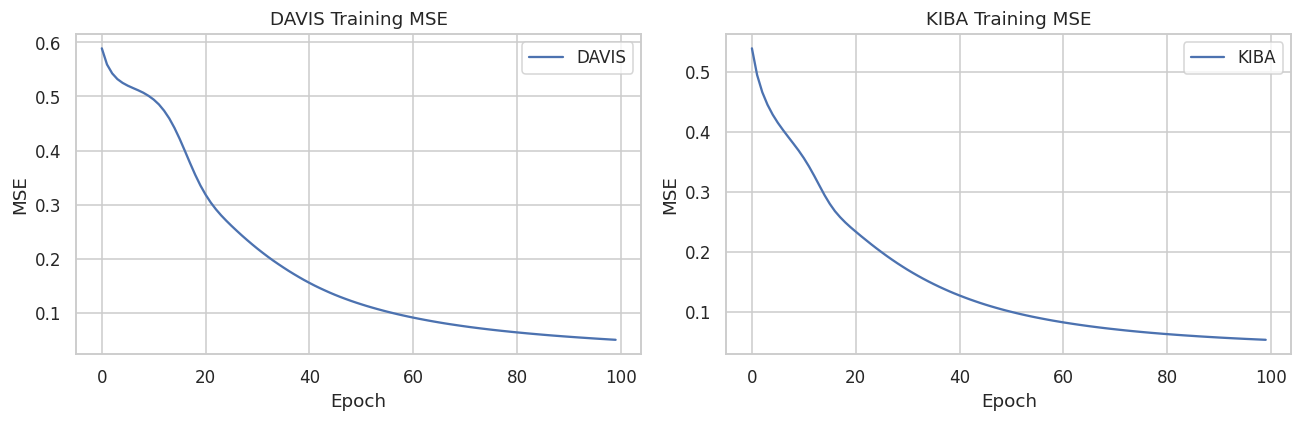

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    best_davis_model.training_history,
    label="DAVIS"
)
axes[0].set_title("DAVIS Training MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()

axes[1].plot(
    best_kiba_model.training_history,
    label="KIBA"
)
axes[1].set_title("KIBA Training MSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/cf_training_convergence.png")
plt.show()